In [1]:
import pandas as pd 
import numpy as np 
import matplotlib.pyplot as plt
import seaborn as sns
import json
import joblib
from pathlib import Path

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.experimental import enable_iterative_imputer  # noqa: F401
from sklearn.impute import SimpleImputer, KNNImputer, IterativeImputer
from sklearn.ensemble import RandomForestRegressor, RandomForestClassifier
from sklearn.metrics import (root_mean_squared_error, mean_absolute_error, r2_score,
                             balanced_accuracy_score, f1_score, make_scorer,
                             ConfusionMatrixDisplay, RocCurveDisplay)
from sklearn.model_selection import StratifiedGroupKFold, cross_val_score, cross_val_predict
from sklearn.dummy import DummyRegressor, DummyClassifier
from sklearn.linear_model import Ridge, LinearRegression
from sklearn.tree import DecisionTreeRegressor
from xgboost import XGBRegressor, XGBClassifier
from sklearn.base import clone
from sklearn.pipeline import make_pipeline
from sklearn.inspection import permutation_importance

from utils_pipeline import WeldImputer, feature_engineering
# régression
from utils_pipeline import metriques, evaluer_cv, resumer
from utils_pipeline import ridge, arbre, random_forest, xgboost, SIMPLICITE
# classification
from utils_pipeline import metriques_cls, evaluer_cv_cls, resumer_cls
from utils_pipeline import logistique, arbre_cls, random_forest_cls, xgboost_cls, SIMPLICITE_cls

# --- Optuna : optimisation bayésienne des hyperparamètres -----------------------------------
import optuna
from optuna.samplers import TPESampler  # échantillonneur TPE, graine fixée pour la reproductibilité
from optuna.trial import TrialState     # filtrage des essais terminés dans les tableaux de résultats

c:\Users\andem\miniconda3\envs\soudure_acier\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
path_data_processed = r"..\1. Données\02_intermediate" + "/welddb_processed_vf.csv"
path_data_correspondance = r"..\1. Données\02_intermediate" + "/correspondance_between_names_units_vf.csv"

df = pd.read_csv(path_data_processed, sep = ";")
correspondance_between_names_units = pd.read_csv(path_data_correspondance, sep = ";")

In [3]:
RANDOM_STATE = 42
TEST_SIZE = 0.2
N_FOLDS = 5
n_TRIALS = 100 #budget d'essaie pour Optuna qui est identique pour chaque modèle optimisé

mask_TARGETS = (correspondance_between_names_units["Role"] == "Quality indicator")
TARGETS = list(set(correspondance_between_names_units.loc[mask_TARGETS, "Feature"])& set(df.columns))
TARGETS_CAT = ["Charpy conforme"]
TARGETS_NUM = list(set(TARGETS) - set(TARGETS_CAT))
ID_COL = "Weld ID"

# ======================================================================
# CIBLE À PRÉDIRE : seule ligne à modifier pour passer d'une cible à l'autre
# ======================================================================
target = "Charpy conforme"
print("Cibles disponibles :", TARGETS)

Cibles disponibles : ['Yield strength', 'Ultimate tensile strength', 'Elongation', 'Reduction of Area', 'Charpy conforme']


# Prédiction des indicateurs de qualité, une cible à la fois

**Objectif :** prédire chacun des 5 indicateurs de qualité d'une soudure à partir de sa composition chimique et de ses paramètres de soudage.

**Mode d'emploi :** pour changer de cible, il suffit de modifier la variable `target` dans la cellule ci-dessus, puis d'exécuter le notebook en entier. Le type de problème s'adapte tout seul :

| Cible | Type | Score de comparaison | Référence naïve |
|---|---|---|---|
| Yield strength, Ultimate tensile strength, Elongation, Reduction of Area | Régression | RMSE (plus bas = mieux) | Prédire la moyenne |
| Charpy conforme | Classification | F1 de la classe 1 (plus haut = mieux, 0 = la classe 1 n'est jamais trouvée) | Prédire la classe majoritaire |

**Démarche, identique pour toutes les cibles :**
1. Séparer les données en train et test, par série de soudure (`Weld ID`).
2. Imputer les valeurs manquantes et créer la variable `CE_IIW`.
3. Réduire le nombre de variables (sélection forward).
4. Comparer plusieurs modèles réglés avec Optuna, puis évaluer le meilleur sur le test.

In [4]:
# Configuration selon le type de cible (régression ou classification)
EST_CLS = target in TARGETS_CAT

if EST_CLS:
    score, sens, direction = "F1", -1, "maximize"                       # sens -1 : plus haut = mieux
    METRIQUES = ["F1", "Accuracy_ponderee", "Precision", "Recall", "ROC_AUC"]
    MODELES = [("Logistique", logistique), ("Arbre", arbre_cls),
               ("Random Forest", random_forest_cls), ("XGBoost", xgboost_cls)]
    SIMPLICITE_ACTIF = SIMPLICITE_cls
    evaluer = evaluer_cv_cls
    metriques_ = lambda yt, yp, proba=None: metriques_cls(yt, yp, proba)
    resumer_ = lambda s: resumer_cls(s, "F1")
    make_baseline = lambda: DummyClassifier(strategy="prior")
    make_xgb_defaut = lambda: XGBClassifier(eval_metric="logloss", n_jobs=-1, random_state=RANDOM_STATE)
    make_rf_forward = lambda: RandomForestClassifier(n_estimators=100, min_samples_leaf=5, class_weight="balanced",
                                                     random_state=RANDOM_STATE, n_jobs=-1)
    scoring_forward = make_scorer(f1_score, zero_division=0)   # F1 sans avertissement si la classe 1 n'est jamais prédite
    NOM_BASELINE, unite = "Baseline (majoritaire)", ""
else:
    score, sens, direction = "RMSE", +1, "minimize"                      # sens +1 : plus bas = mieux
    METRIQUES = ["RMSE", "MAE", "R2"]
    MODELES = [("Ridge", ridge), ("Arbre", arbre),
               ("Random Forest", random_forest), ("XGBoost", xgboost)]
    SIMPLICITE_ACTIF = SIMPLICITE
    evaluer = evaluer_cv
    metriques_ = lambda yt, yp, proba=None: metriques(yt, yp)
    resumer_ = lambda s: resumer(s, "RMSE")
    make_baseline = lambda: DummyRegressor()
    make_xgb_defaut = lambda: XGBRegressor(n_jobs=-1, random_state=RANDOM_STATE)
    make_rf_forward = lambda: RandomForestRegressor(n_estimators=100, random_state=RANDOM_STATE, n_jobs=-1)
    scoring_forward = "neg_root_mean_squared_error"
    NOM_BASELINE = "Baseline (moyenne)"
    unite_df = correspondance_between_names_units.loc[correspondance_between_names_units["Feature"] == target, "Unit"]
    unite = f" ({unite_df.values[0]})" if len(unite_df) else ""

print(f"Cible : {target} -> {'classification' if EST_CLS else 'régression'} (score de comparaison : {score})")

Cible : Charpy conforme -> classification (score de comparaison : F1)


## 1. Données et séparation train/test

Le projet cherche à prédire la qualité d'une soudure d'acier. Aucune variable ne porte ce nom : nous avons **5 indicateurs de qualité**, que nous prédisons un par un avec une démarche classique, vue en TD. Il y a donc cinq modèles différents, de régression ou de classification.

Commençons par regarder les 5 cibles : leur distribution, et le nombre de lignes renseignées pour chacune.

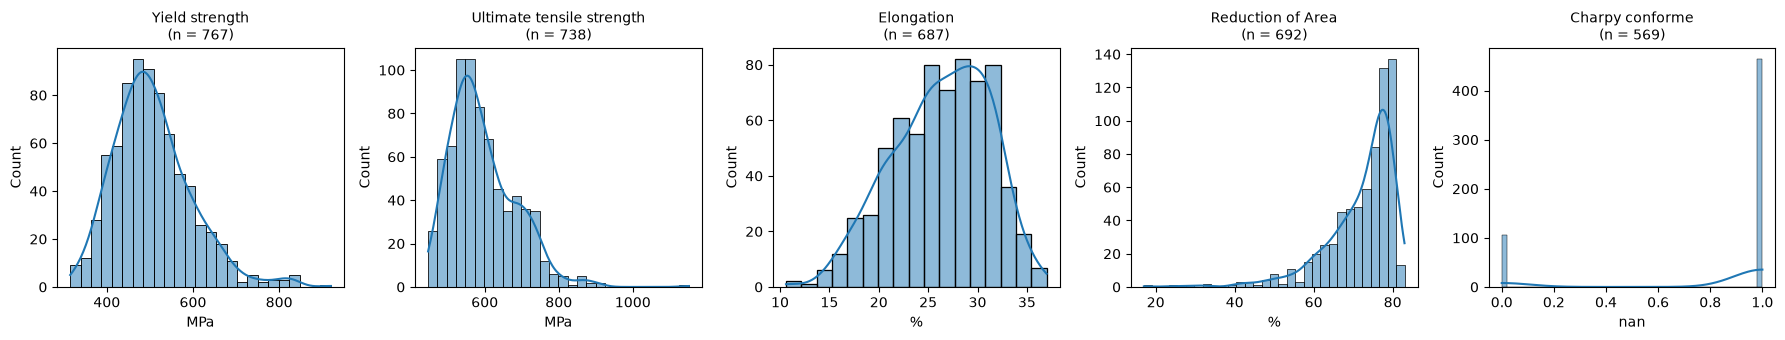

,count,mean,std,min,25%,50%,75%,max
Yield strength,767.0,506.4,91.3,315.0,443.0,494.0,555.0,920.0
Ultimate tensile strength,738.0,594.4,88.6,447.0,532.8,575.5,647.0,1151.0
Elongation,687.0,26.3,4.9,10.6,23.0,26.8,30.0,37.0
Reduction of Area,692.0,72.0,8.8,17.0,68.5,75.0,78.0,83.0
Charpy conforme,569.0,0.8,0.4,0.0,1.0,1.0,1.0,1.0


In [5]:
# distributions des targets 
fig, axes = plt.subplots(1, len(TARGETS), figsize=(18, 3.5))
for ax, t in zip(axes, TARGETS):
    sns.histplot(df[t].dropna(), ax=ax, kde=True)
    ax.set_title(f"{t}\n(n = {df[t].notna().sum()})", fontsize=10)
    ax.set_xlabel(correspondance_between_names_units.loc[correspondance_between_names_units['Feature'] == t, 'Unit'].values[0])
plt.tight_layout()
plt.show()

df[TARGETS].describe().T.round(1)

Yield strength               767
Ultimate tensile strength    738
Elongation                   687
Reduction of Area            692
Charpy conforme              569

Lignes avec au moins une cible : 1245
Lignes avec toutes les cibles  : 118
Lignes sans aucune cible       : 393


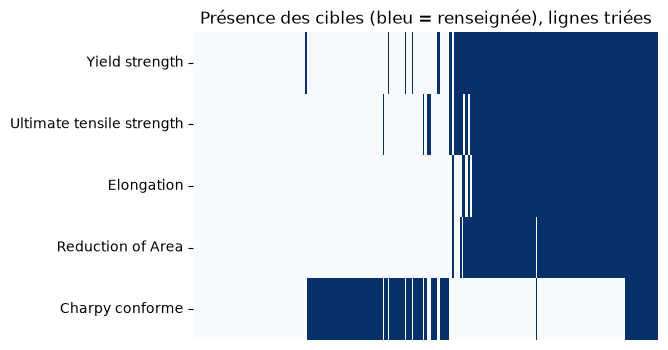

In [6]:
# observons la répartition des instances manquantes par cible
target_counts = df[TARGETS].notna().sum().rename("nb lignes étiquetées")
print(target_counts.to_string())
print(f"\nLignes avec au moins une cible : {df[TARGETS].notna().any(axis=1).sum()}")
print(f"Lignes avec toutes les cibles  : {df[TARGETS].notna().all(axis=1).sum()}")
print(f"Lignes sans aucune cible       : {df[TARGETS].isna().all(axis=1).sum()}")

plt.figure(figsize=(6, 4))
sns.heatmap(df[TARGETS].notna().T.astype(int).loc[:, df[TARGETS].notna().sum(axis=1).sort_values().index],
            cbar=False, cmap="Blues", xticklabels=False)
plt.title("Présence des cibles (bleu = renseignée), lignes triées")
plt.show()

On retient trois points :
- **Type de problème :** seule `Charpy conforme` est catégorielle (classification). Les quatre autres sont numériques (régression).
- **Lignes utilisées :** toutes les cibles ne sont pas renseignées sur les mêmes lignes. Pour chaque cible, on garde uniquement les lignes où elle existe : sans valeur réelle, on ne peut pas évaluer la prédiction. Pour exploiter les autres lignes, il faudrait passer à de l'apprentissage semi-supervisé (partie traitée plus tard).
- **Distribution :** les cibles sont loin d'être gaussiennes. On fait donc une **stratification**, pour que le train et le test aient la même distribution de la cible. En régression, on stratifie sur 5 tranches de quantiles de la cible. En classification, on stratifie sur les classes.

**Séries de soudure.** Les lignes issues d'un même `Weld ID` sont très similaires. Pour éviter une fuite de données, elles doivent se trouver du même côté : toutes dans le train, ou toutes dans le test. Nous utilisons donc `StratifiedGroupKFold`, qui répartit des groupes entiers dans K paquets tout en gardant une distribution de la cible proche dans chacun. Le premier fold sert de split train/test (environ 80/20).

In [7]:
# Split des données en stratifiant et en fonction du Weld ID
d = df[df[target].notna()].reset_index(drop=True)   # on ne garde que les lignes où la cible existe

# On retire toutes les cibles des features (elles seraient une fuite)
X = d.drop(columns=TARGETS+[ID_COL])
y = d[target].astype(int) if EST_CLS else d[target]
groups = d[ID_COL]

# Stratification : classes (classification) ou quantiles de la cible (régression)
y_bins = y if EST_CLS else pd.qcut(y, q=5, labels=False, duplicates="drop")

# 5 folds, soit environ 80/20 ; on prend le premier comme train/test
sgkf = StratifiedGroupKFold(n_splits=N_FOLDS, shuffle=True, random_state=RANDOM_STATE)
train_idx, test_idx = next(sgkf.split(X, y_bins, groups))

X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]

# Vérifications
print(len(train_idx), len(test_idx))
print(set(groups.iloc[train_idx]) & set(groups.iloc[test_idx]))   # doit être vide
print(y_train.describe(), y_test.describe())

461 108
set()
count    461.000000
mean       0.809111
std        0.393429
min        0.000000
25%        1.000000
50%        1.000000
75%        1.000000
max        1.000000
Name: Charpy conforme, dtype: float64 count    108.000000
mean       0.842593
std        0.365882
min        0.000000
25%        1.000000
50%        1.000000
75%        1.000000
max        1.000000
Name: Charpy conforme, dtype: float64


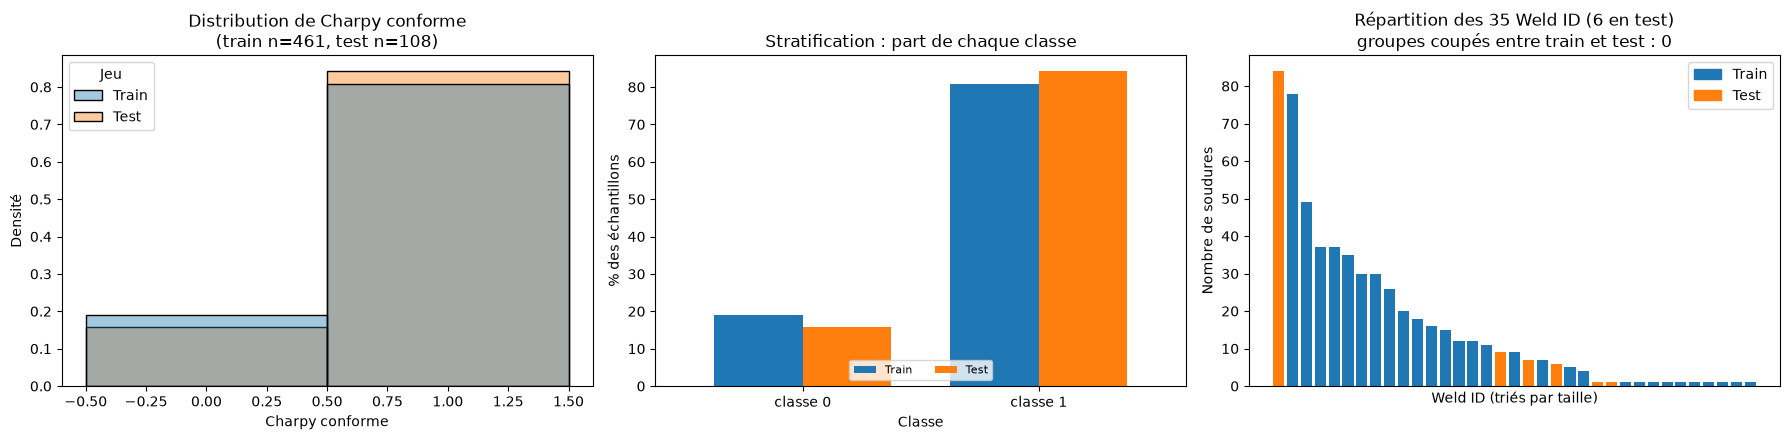

In [8]:
# Étiquette Train/Test pour chaque ligne de d
split = pd.Series("Train", index=d.index, name="Jeu")
split.iloc[test_idx] = "Test"
palette = {"Train": "#1f77b4", "Test": "#ff7f0e"}

fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))

# 1) Distribution de la cible (densité, pour comparer malgré les tailles différentes)
ax = axes[0]
sns.histplot(x=y, hue=split, stat="density", common_norm=False, kde=not EST_CLS,
             discrete=EST_CLS, bins=25, palette=palette, alpha=0.4, ax=ax)
ax.set_title(f"Distribution de {target}\n(train n={len(y_train)}, test n={len(y_test)})")
ax.set_xlabel(f"{target}{unite}"); ax.set_ylabel("Densité")

# 2) Proportion de chaque classe / tranche de quantile dans train et test
ax = axes[1]
props = (pd.crosstab(y_bins, split, normalize="columns") * 100)[["Train", "Test"]]
if EST_CLS:
    props.index = [f"classe {i}" for i in props.index]
    ax.set_title("Stratification : part de chaque classe")
    ax.set_xlabel("Classe")
else:
    edges = pd.qcut(y, q=5, retbins=True, duplicates="drop")[1]
    props.index = [f"{edges[i]:.0f}–{edges[i+1]:.0f}" for i in props.index]
    ax.axhline(20, ls="--", c="grey", lw=1, label="20 % attendu")
    ax.set_title("Stratification : part de chaque tranche de y")
    ax.set_xlabel(f"Tranche de {target}{unite}")
props.plot.bar(ax=ax, color=[palette["Train"], palette["Test"]], rot=0, width=0.75)
ax.set_ylabel("% des échantillons")
ax.legend(loc="lower center", ncol=3, fontsize=8)

# 3) Groupes : chaque barre = un Weld ID, colorée selon le côté où il est tombé
ax = axes[2]
g = (pd.DataFrame({"Weld ID": groups, "split": split})
       .groupby("Weld ID").agg(n=("split", "size"), split=("split", "first"))
       .sort_values("n", ascending=False))
n_split_groups = (pd.crosstab(groups, split) > 0).sum(axis=1).gt(1).sum()
ax.bar(range(len(g)), g["n"], color=g["split"].map(palette), width=0.8)
ax.set_title(f"Répartition des {len(g)} Weld ID ({(g['split']=='Test').sum()} en test)\n"
             f"groupes coupés entre train et test : {n_split_groups}")
ax.set_xlabel("Weld ID (triés par taille)"); ax.set_ylabel("Nombre de soudures")
ax.set_xticks([])
ax.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=c) for c in palette.values()],
          labels=list(palette.keys()))

plt.tight_layout()
plt.show()

Les trois graphiques montrent que :
- la distribution de la cible est très proche dans le train et dans le test ;
- la stratification fonctionne : chaque classe (ou chaque tranche de quantile, environ 20 % en régression) est présente dans les mêmes proportions des deux côtés ;
- chaque barre est une série de soudure, entièrement dans le train ou entièrement dans le test (aucun groupe coupé).

Comme le test contient peu de séries, le score dépend un peu des séries tirées. C'est pourquoi on utilise aussi une validation croisée, pour obtenir une mesure plus stable.

**À partir de maintenant, les données de test ne sont plus utilisées**, sauf pour l'évaluation finale du modèle.

## 2. Imputation et feature engineering

On impute les valeurs manquantes avec `WeldImputer` (défini dans `utils_pipeline.py`). Toutes les statistiques d'imputation sont **apprises sur le train**, puis appliquées au test.

In [9]:
imp = WeldImputer()
X_train_imp = imp.fit_transform(X_train)   # fit sur le train uniquement
X_test_imp  = imp.transform(X_test)        # on applique les statistiques du train

print(X_train_imp.isna().sum()[lambda s: s > 0])   # NaN restants
print(X_test_imp.isna().sum()[lambda s: s > 0])

Series([], dtype: int64)
Series([], dtype: int64)


On crée ensuite la variable `CE_IIW` (carbone équivalent), définie dans le notebook 2.

In [10]:
X_train_fe = feature_engineering(X_train_imp)
X_test_fe  = feature_engineering(X_test_imp)

print(X_train_fe["CE_IIW"].describe())
print(X_train_fe["CE_IIW"].isna().sum(), X_test_fe["CE_IIW"].isna().sum())   # doit être 0 et 0

count    461.000000
mean       0.487444
std        0.508993
min        0.158000
25%        0.277383
50%        0.315050
75%        0.393050
max        2.327667
Name: CE_IIW, dtype: float64
0 0


In [11]:
# Variables après imputation (noms utilisés pour la sélection)
COL_CAT = ["Type of weld", "courant"]
COL_NUM = [c for c in X_train_fe.columns if c not in COL_CAT]

## 3. Réduction du nombre de variables

#### Sélection forward

Plusieurs méthodes existent pour réduire le nombre de variables. Nous écartons deux d'entre elles :
- **la PCA**, car ses axes sont plus difficiles à interpréter que les variables elles-mêmes ;
- **le filtre par corrélation**, car il demande trois calculs différents ($\chi^2$ entre variables catégorielles, corrélation de Spearman entre variables numériques, $\eta$ entre les deux) et il faut ensuite décider quelles variables supprimer.

Nous testons donc la **sélection forward** : on part sans variable, puis on ajoute à chaque étape celle qui améliore le plus le modèle. On obtient une suite de modèles $\mathcal{M}_0, \mathcal{M}_1, \dots$ et on choisit la meilleure taille $\mathcal{M}_k$ par **validation croisée**, avec un Random Forest comme modèle de référence. Le score utilisé est le RMSE en régression et le F1 en classification.

In [12]:
# Pipeline pour l'encodage et la standardisation, et le modèle
def make_model(feats, model):
    preprocessor = ColumnTransformer([
        ("num", StandardScaler(), [c for  c in feats if c in COL_NUM]),
        ("cat", OneHotEncoder(handle_unknown="ignore"), [c for c in feats if c in COL_CAT]),
    ])
    return make_pipeline(preprocessor, clone(model))

In [13]:
# Sélection forward basée sur un algorithme de glouton
def forward_stepwise(X, y, model, cv, scoring):
    def train_score(feats):
        """Étape : score sur l'entraînement (sans validation croisée) : R² ou F1."""
        pipe = make_model(feats, model)
        pipe.fit(X[feats], y)
        pred = pipe.predict(X[feats])
        return f1_score(y, pred, zero_division=0) if EST_CLS else r2_score(y, pred)

    def cv_score(feats):
        """Étape : score en validation croisée (M0 = modèle nul)."""
        if not feats:  # M_0 : prédit la moyenne (ou la classe majoritaire), aucune variable
            pipe = make_baseline()
            return cross_val_score(pipe, X, y, cv=cv, scoring=scoring).mean()
        pipe = make_model(feats, model)
        return cross_val_score(pipe, X[feats], y, cv=cv, scoring=scoring).mean()

    features = list(X.columns)
    selected = []
    models = [[]]                      # M_0 : modèle nul (aucune variable)

    while len(selected) < len(features):
        candidates = [selected + [f] for f in features if f not in selected]  # (a)
        scores = [train_score(c) for c in candidates]                         # (b)
        best = int(np.argmax(scores))
        selected = candidates[best]
        models.append(list(selected))

    cv_scores = [cv_score(feats) for feats in models]
    best_k = int(np.argmax(cv_scores))
    best_feats = models[best_k]

    return models, cv_scores, best_feats

In [14]:
folds = list(sgkf.split(X_train_fe, y_bins.iloc[train_idx], groups.iloc[train_idx]))

models, cv_scores, best_feats = forward_stepwise(
    X_train_fe, y_train,
    model=make_rf_forward(),
    scoring=scoring_forward,
    cv=folds,
)

best_score = max(cv_scores)

best_k = cv_scores.index(best_score)

if EST_CLS:
    print(f"Meilleur F1 : {best_score:.3f} avec {len(best_feats)} variables")
else:
    print(f"Meilleure RMSE : {-best_score:.2f}{unite} avec {len(best_feats)} variables")

# garantie que la variable "Carbon concentration" est conservée
if "Carbon concentration" not in best_feats:
    best_feats.append("Carbon concentration")
    
print("Variables gardées :", best_feats)
print("Variables supprimées :", [f for f in X_train_fe.columns if f not in best_feats])
print(f"{len(best_feats)} variables gardées sur {X_train_fe.shape[1]}")

Meilleur F1 : 0.961 avec 5 variables
Variables gardées : ['Chromium concentration', 'Voltage', 'Silicon concentration', 'Titanium concentration', 'Oxygen concentration', 'Carbon concentration']
Variables supprimées : ['Manganese concentration', 'Sulphur concentration', 'Phosphorus concentration', 'Nickel concentration', 'Molybdenum concentration', 'Vanadium concentration', 'Copper concentration', 'Nitrogen concentration', 'Aluminium concentration', 'Boron concentration', 'Niobium concentration', 'Current', 'Heat input', 'Interpass temperature', 'Type of weld', 'Post weld heat treatment temperature', 'Post weld heat treatment time', 'courant', 'CE_IIW']
6 variables gardées sur 25


La sélection retient un sous-ensemble de variables. `Carbon concentration` est ajouté s'il n'en fait pas partie, car la littérature montre qu'il apporte un durcissement en solution solide et augmente la trempabilité et la formation de carbures.

Si une grande part des variables est retirée, il est prudent de comparer aussi avec une version **sans sélection**. C'est ce que font les parties A et B de la section suivante.

Le graphique ci-dessous montre le score de validation en fonction du nombre de variables. Le cercle rouge indique la taille retenue.

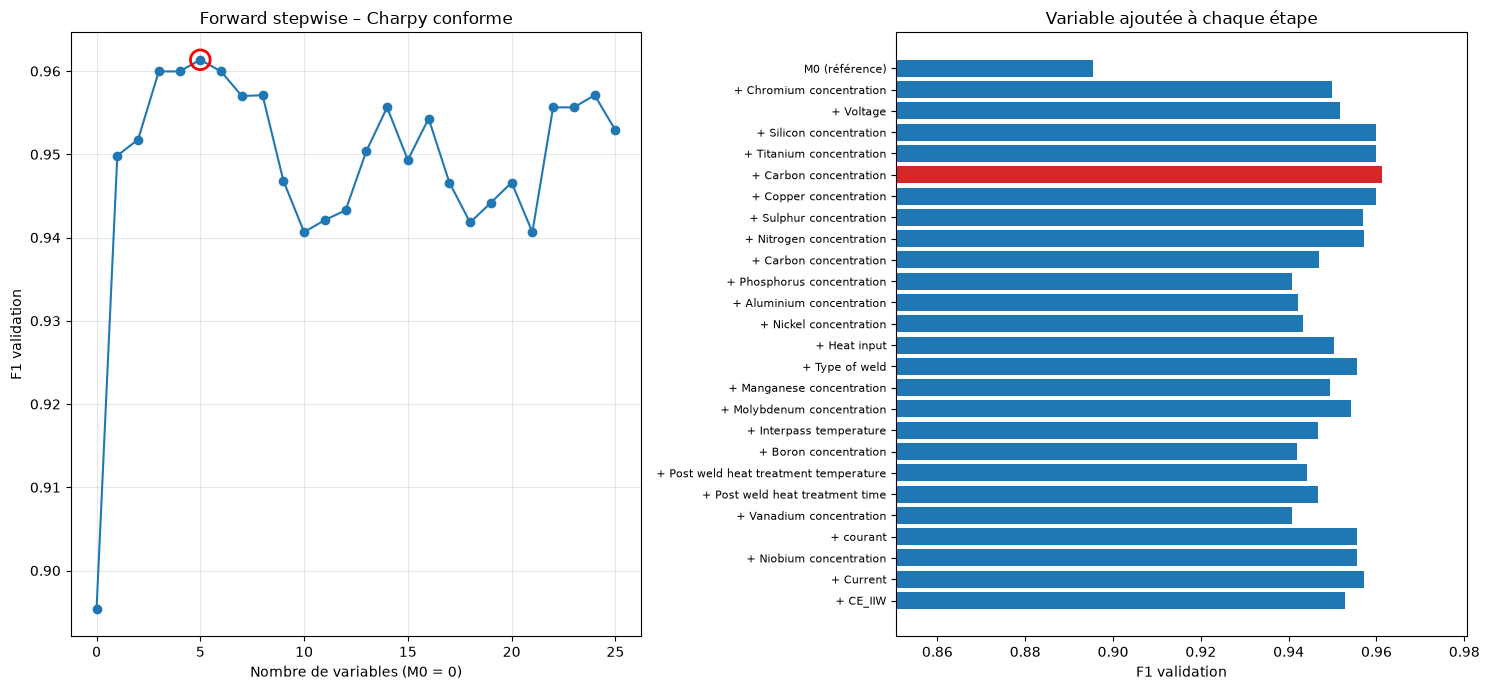

In [15]:
# valeurs à tracer : RMSE (à minimiser) ou F1 (à maximiser)
perf = list(cv_scores) if EST_CLS else [-s for s in cv_scores]
labels = ["M0 (référence)" if not f else "+ " + f[-1] for f in models]
i_best = int(np.argmax(perf)) if EST_CLS else int(np.argmin(perf))
nom_perf = "F1" if EST_CLS else "RMSE"

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 7))

# --- Courbe du score vs nombre de variables (M0 = 0 variable) ---
ax1.plot(range(len(perf)), perf, marker="o")
ax1.scatter(i_best, perf[i_best], s=200, facecolors="none",
           edgecolors="red", linewidths=2, zorder=3)
ax1.set_xlabel("Nombre de variables (M0 = 0)")
ax1.set_ylabel(f"{nom_perf} validation{unite}")
ax1.set_title(f"Forward stepwise – {target}")
ax1.grid(alpha=0.3)

# --- Barres : variable ajoutée à chaque étape ---
colors = ["tab:red" if i == i_best else "tab:blue" for i in range(len(perf))]
ax2.barh(range(len(perf)), perf, color=colors)
ax2.set_yticks(range(len(perf)), labels, fontsize=8)
ax2.invert_yaxis()
ax2.set_xlim(min(perf) * 0.95, max(perf) * 1.02)
ax2.set_xlabel(f"{nom_perf} validation{unite}")
ax2.set_title("Variable ajoutée à chaque étape")

plt.tight_layout()
plt.show()

## 4. Sélection de modèle

On compare quatre modèles, dans leur version régression ou classification :

| Régression | Classification |
|---|---|
| Ridge (régression linéaire régularisée) | Régression logistique régularisée |
| Arbre de décision | Arbre de décision |
| Random Forest (bagging) | Random Forest (bagging) |
| XGBoost (boosting) | XGBoost (boosting) |

Les hyperparamètres de chaque modèle sont choisis avec **Optuna**, puis le modèle le plus simple parmi les meilleurs est retenu (règle 1-SE, expliquée ci-dessous).

#### Fonctions utiles

In [16]:
def construire_prep(COL_NUM, COL_CAT):
    return ColumnTransformer([
        ("num", "passthrough", COL_NUM),
        ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), COL_CAT),
    ])

La fonction `optimiser` choisit les hyperparamètres d'un modèle avec **Optuna** (algorithme TPE, graine fixée pour être reproductible). Elle optimise le score moyen en **validation croisée groupée** sur le train. Le prétraitement est inclus dans le pipeline : il est donc refait sur le train de chaque pli, sans fuite de données.

**Règle de l'erreur standard (« 1-SE »).** Garder simplement le meilleur essai est fragile : avec peu de séries de soudure, l'écart entre deux essais est souvent plus petit que le bruit de la validation croisée. On procède donc en trois temps :

1. On calcule l'erreur standard du meilleur essai : $SE = \dfrac{\sigma}{\sqrt{K}}$, avec $\sigma$ l'écart-type du score entre les plis et $K$ le nombre de plis.
2. On garde tous les essais « indiscernables » du meilleur, c'est-à-dire ceux dont le score est à moins de 1 SE du meilleur.
3. Parmi eux, on retient le **modèle le plus simple**, selon un critère fixé à l'avance pour chaque modèle (`SIMPLICITE` : par exemple une profondeur plus faible ou une régularisation plus forte).

À performance équivalente, un modèle plus simple surapprend moins et généralise mieux à de nouvelles séries de soudure.

La fonction réévalue ensuite le modèle retenu en validation croisée (résultats stockés dans `registre[nom]`), affiche le nombre d'essais indiscernables, et renvoie le pipeline et ses hyperparamètres.

In [17]:
def optimiser(nom, construire_modele, X_train, y_train,construire_prep, registre, n_trials=n_TRIALS):
    """Recherche les hyperparamètres d'un modèle avec Optuna, puis retient le modèle
    le plus simple parmi les essais statistiquement équivalents au meilleur (règle 1-SE)."""

    def objective(trial):
        # Pipeline complet : prétraitement + modèle dont les hyperparamètres sont proposés par Optuna
        # (le prétraitement est refait sur le train de chaque pli : pas de fuite)
        pipe = make_pipeline(construire_prep, construire_modele(trial))
        # Validation croisée groupée : renvoie les scores de chaque pli
        res = evaluer(pipe, X_train, y_train, folds)
        # Erreur standard du score = écart-type entre plis / racine du nb de plis
        # (stockée dans l'essai pour la règle 1-SE plus bas)
        trial.set_user_attr("se", res[score].std() / np.sqrt(len(folds)))
        # Valeur optimisée : score moyen sur les plis (RMSE à minimiser, F1 à maximiser)
        return res[score].mean()

    # Étude Optuna : algorithme TPE, graine fixée = reproductible
    study = optuna.create_study(direction=direction, sampler=TPESampler(seed=RANDOM_STATE))
    study.optimize(objective, n_trials=n_trials)
    # On ne garde que les essais terminés (on écarte les essais échoués ou élagués)
    essais = [t for t in study.trials if t.state == TrialState.COMPLETE]
    # Règle 1-SE : on accepte un score à moins de 1 SE du meilleur (dans le mauvais sens)
    se = study.best_trial.user_attrs["se"]
    indisc = [t for t in essais if sens * (t.value - study.best_value) <= se]
    # Parmi eux, on retient le plus simple selon le critère propre au modèle
    # (ex. profondeur plus faible, régularisation plus forte)
    retenu = min(indisc, key=lambda t: SIMPLICITE_ACTIF[nom](t.params))
    # Reconstruit le pipeline avec les hyperparamètres de l'essai retenu
    # (FixedTrial rejoue ces valeurs dans construire_modele)
    modele = make_pipeline(construire_prep,
                           construire_modele(optuna.trial.FixedTrial(retenu.params)))
    # Réévalue le modèle retenu en CV et stocke les résultats dans le registre global
    registre[nom] = evaluer(modele, X_train, y_train, folds)
    # Résumé : combien d'essais sont équivalents au meilleur, lequel est retenu
    print(f"{nom} : {len(indisc)}/{len(essais)} essais indiscernables, "
          f"retenu n°{retenu.number} ({retenu.value:.3f} vs meilleur {study.best_value:.3f})")
    # Renvoie le pipeline (non entraîné) et ses hyperparamètres
    return modele, retenu.params

La fonction suivante enregistre **tous les résultats** d'une analyse (une cible, une méthode) dans le dossier `05_reporting/prediction_par_cible/<cible>/<méthode>/` : tableaux de validation croisée, finalistes, prédictions du test, intervalle de confiance, variables retenues, importances, hyperparamètres et modèle entraîné. Un notebook de reprise peut donc tout relire avec `charger_analyse(cible, methode)`, sans relancer l'optimisation.

In [18]:
DOSSIER_REPORTING = Path("..") / "1. Données" / "05_reporting" / f"prediction_{target}"


def enregistrer_analyse(methode, forward=None):
    """Enregistre les résultats de la cible `target` pour la méthode `methode`
    ("A_sans_selection" ou "B_avec_selection") dans 05_reporting/prediction_par_cible/<cible>/<methode>/.
    forward : (models, cv_scores, best_feats) renvoyé par forward_stepwise (méthode B seulement)."""
    dossier_cible = DOSSIER_REPORTING / target.replace(" ", "_")
    dossier = dossier_cible / methode
    dossier.mkdir(parents=True, exist_ok=True)
    csv = dict(sep=";", encoding="utf-8-sig")

    # --- 1) Commun aux deux méthodes : découpage train/test et imputeur ----------------
    y_tout = pd.Series(np.nan, index=d.index)
    y_tout.iloc[train_idx], y_tout.iloc[test_idx] = y_train.values, y_test.values
    pd.DataFrame({"position_dans_d": d.index, "Weld ID": groups.values,
                  "jeu": split.values, "cible": y_tout.values}
                 ).to_csv(dossier_cible / "split_train_test.csv", index=False, **csv)
    joblib.dump(imp, dossier_cible / "imputer.joblib")

    # --- 2) Validation croisée : comparaison des modèles réglés ------------------------
    tableau.to_csv(dossier / "cv_comparaison_modeles.csv", **csv)
    (pd.concat(registre, names=["modele", "fold"]).reset_index()
       .to_csv(dossier / "cv_scores_par_fold.csv", index=False, **csv))

    # --- 3) Départage des finalistes (nouveaux découpages) -----------------------------
    reeval.to_csv(dossier / "finalistes_reeval_brut.csv", index=False, **csv)
    resume.to_csv(dossier / "finalistes_resume.csv", **csv)
    comp.to_csv(dossier / "finalistes_comparaisons_appariees.csv", **csv)

    # --- 4) Évaluation finale sur le test ----------------------------------------------
    recap.to_csv(dossier / "test_recap_metriques.csv", **csv)
    pred = res_test[[c for c in ["groupe", "reel", "predit", "proba"] if c in res_test.columns]].copy()
    pred.insert(0, "position_dans_d", test_idx)
    pred.to_csv(dossier / "test_predictions.csv", index=False, **csv)
    pd.Series(boot_score, name="score_bootstrap").to_csv(dossier / "test_bootstrap.csv", index=False, **csv)

    # --- 5) Variables, importances, sélection forward (si disponibles) ------------------
    pd.DataFrame({"variable": X_train_fe.columns,
                  "retenue": [c in X_train_red.columns for c in X_train_fe.columns]}
                 ).to_csv(dossier / "variables.csv", index=False, **csv)
    for nom_df, fichier in [("importance_df", "importance_permutation_retenu.csv"),
                            ("imp_rf_df", "importance_permutation_random_forest.csv"),
                            ("comparaison", "test_comparaison_random_forest.csv")]:
        if nom_df in globals():
            globals().pop(nom_df).to_csv(dossier / fichier, **csv)   # retiré ensuite : pas de reste pour la méthode suivante
    if forward is not None:
        models_f, cv_scores_f, _ = forward
        pd.DataFrame({"etape": range(len(models_f)),
                      "variable_ajoutee": ["(modèle nul)" if not f else f[-1] for f in models_f],
                      "nb_variables": [len(f) for f in models_f],
                      "score_cv": cv_scores_f,
                      "variables": [" | ".join(f) for f in models_f]}
                     ).to_csv(dossier / "selection_forward.csv", index=False, **csv)

    # --- 6) Modèle retenu (réutilisable sans réentraîner) + paramètres ------------------
    joblib.dump(modele_final, dossier / "modele_final.joblib")
    infos = {
        "cible": target, "type": "classification" if EST_CLS else "régression", "methode": methode,
        "score_de_selection": score, "modele_retenu": nom_final,
        "hyperparametres_retenu": params[nom_final],
        "hyperparametres_tous_modeles": params,
        "variables_utilisees": list(X_train_red.columns),
        "score_test": {k: float(v) for k, v in score_test.items()},
        "ic95_test_bootstrap": [float(ic_bas), float(ic_haut)],
        "score_cv_finaliste": [float(score_cv), float(cv_bas), float(cv_haut)],
        "RANDOM_STATE": RANDOM_STATE, "SEED_REEVAL": SEED_REEVAL, "N_REPETITIONS": N_REPETITIONS,
        "N_FOLDS": N_FOLDS, "n_TRIALS": n_TRIALS, "TEST_SIZE": TEST_SIZE,
    }
    with open(dossier / "modele_retenu.json", "w", encoding="utf-8") as f:
        json.dump(infos, f, indent=2, ensure_ascii=False,
                  default=lambda o: o.item() if hasattr(o, "item") else str(o))

    # --- 7) Tableau de synthèse de toutes les cibles et méthodes ------------------------
    ligne = {"cible": target, "methode": methode, "type": infos["type"],
             "modèle retenu": nom_final, "score": score,
             "CV": cv_final[score], "test": score_test[score],
             "IC95 test bas": ic_bas, "IC95 test haut": ic_haut,
             "baseline test": score_base[score]}
    fichier = DOSSIER_REPORTING.parent / "resultats_par_cible.csv"
    if fichier.exists():
        tab = pd.read_csv(fichier, sep=";", encoding="utf-8-sig")
        tab = tab[~((tab["cible"] == target) & (tab["methode"] == methode))]
        tab = pd.concat([tab, pd.DataFrame([ligne])], ignore_index=True)
    else:
        tab = pd.DataFrame([ligne])
    tab.to_csv(fichier, index=False, **csv)

    print(f"{target} — « {methode} » enregistrée dans : {dossier.resolve()}")
    print(*sorted(p.name for p in dossier.iterdir()), sep="\n  - ")


def charger_analyse(cible, methode):
    """Recharge une analyse enregistrée (pour reprendre le travail dans un autre notebook)."""
    dossier = DOSSIER_REPORTING / cible.replace(" ", "_") / methode
    res = {p.stem: pd.read_csv(p, sep=";", encoding="utf-8-sig") for p in dossier.glob("*.csv")}
    res["infos"] = json.load(open(dossier / "modele_retenu.json", encoding="utf-8"))
    res["modele_final"] = joblib.load(dossier / "modele_final.joblib")
    return res

#### A. Méthode sans sélection de variables

Toutes les variables sont conservées. Les plis de validation croisée sont **les mêmes pour tous les modèles** (groupés sur `Weld ID`, stratifiés), ce qui rend la comparaison équitable.

In [19]:
# ==================================================================
# 0) Données : toutes les variables sont conservées
# ==================================================================
# Folds : les MÊMES pour tous les modèles, groupés sur Weld ID, calculés sur tout X_train
groups_train = groups.iloc[train_idx]
y_bins_train = y_bins.iloc[train_idx]
sgkf = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
folds = list(sgkf.split(X_train_fe, y_bins_train, groups_train))
COL_NUM_RED = COL_NUM
COL_CAT_RED = COL_CAT
X_train_red = X_train_fe
X_test_red = X_test_fe

**Comparaison des modèles réglés.** On évalue d'abord la référence naïve (rien à régler), puis chaque modèle avec Optuna et la règle 1-SE, avec le même budget d'essais pour tous.

In [20]:
registre = {}   # nom du modèle -> DataFrame des scores par fold

# Affichage des erreurs pour l'optimisation
optuna.logging.set_verbosity(optuna.logging.ERROR)

# Référence naïve : prédit toujours la moyenne (régression) ou la classe majoritaire (classification)
registre[NOM_BASELINE] = evaluer(make_pipeline(construire_prep(COL_NUM_RED, COL_CAT_RED), make_baseline()),
                                 X_train_red, y_train, folds)

modeles, params = {}, {}

# Modèles avec hyperparamètres réglés par Optuna
for nom, fn in MODELES:
    modeles[nom], params[nom] = optimiser(nom, fn, X_train_red, y_train, construire_prep(COL_NUM_RED, COL_CAT_RED), registre, n_trials=n_TRIALS)

Logistique : 82/100 essais indiscernables, retenu n°35 (0.915 vs meilleur 0.933)
Arbre : 20/100 essais indiscernables, retenu n°67 (0.935 vs meilleur 0.935)
Random Forest : 89/100 essais indiscernables, retenu n°25 (0.936 vs meilleur 0.946)
XGBoost : 82/100 essais indiscernables, retenu n°72 (0.944 vs meilleur 0.952)


                        moyenne  ecart_type     SE  pire_fold
XGBoost                   0.944       0.051  0.023      0.868
Random Forest             0.936       0.046  0.020      0.868
Arbre                     0.935       0.023  0.010      0.902
Logistique                0.915       0.066  0.030      0.824
Baseline (majoritaire)    0.895       0.035  0.015      0.834


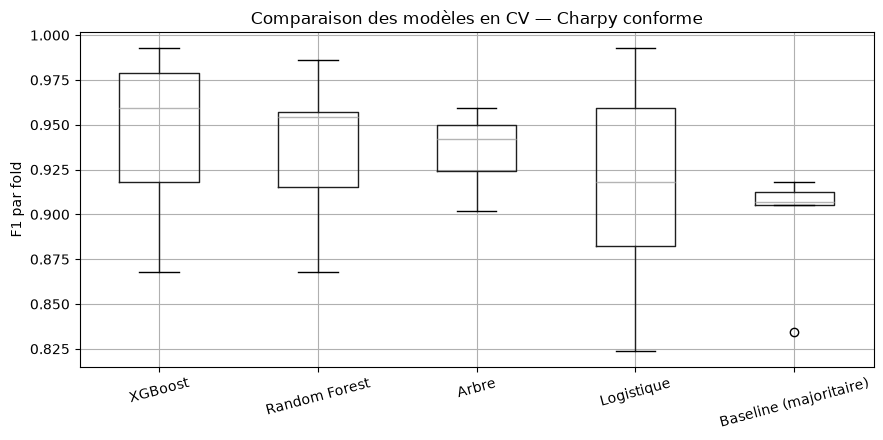

In [21]:
# 5) Comparaison des modèles réglés
tableau = (pd.DataFrame({nom: resumer_(s) for nom, s in registre.items()}).T
           .sort_values("moyenne", ascending=(sens == 1)))
print(tableau.round(3))

# Boxplot du score par fold
fig, ax = plt.subplots(figsize=(9, 4.5))
pd.DataFrame({nom: s[score] for nom, s in registre.items()})[tableau.index].boxplot(ax=ax)
ax.set_ylabel(f"{score} par fold{unite}")
ax.set_title(f"Comparaison des modèles en CV — {target}")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

**Choix des finalistes.** Pour mesurer l'apport réel de l'optimisation, on ajoute un **XGBoost avec ses hyperparamètres par défaut**, évalué avec les mêmes variables et les mêmes plis. Si les modèles optimisés ne le battent pas nettement, le réglage n'apporte rien.

Les **finalistes** sont les deux meilleurs modèles optimisés du tableau précédent et ce XGBoost par défaut. Seuls ces trois modèles passent à l'étape suivante, ce qui limite le risque de surestimer la performance en choisissant parmi trop de candidats.

In [22]:
# ==================================================================
# 5 bis) Choix des finalistes (aucune décision ici)
# ==================================================================
# Version par défaut : mesure le gain réel de l'optimisation
modeles["XGBoost (défaut)"] = make_pipeline(
    construire_prep(COL_NUM_RED, COL_CAT_RED), make_xgb_defaut())
params["XGBoost (défaut)"] = {}
registre["XGBoost (défaut)"] = evaluer(modeles["XGBoost (défaut)"],
                                       X_train_red, y_train, folds)

# Les 2 meilleurs modèles optimisés du benchmark + la version par défaut
top2 = [n for n in tableau.index if n in modeles][:2]
FINALISTES = top2 + ["XGBoost (défaut)"]
print("Finalistes :", FINALISTES)

Finalistes : ['XGBoost', 'Random Forest', 'XGBoost (défaut)']


**Départage des finalistes sur de nouveaux découpages.** Le classement précédent dépend du découpage en plis. Pour le rendre plus fiable, on répète la validation croisée avec **100 graines différentes** (hyperparamètres figés), ce qui donne 100 × 5 évaluations par modèle.

La règle de choix est fixée **avant** le calcul : le modèle retenu est celui dont le score moyen sur toutes les répétitions est le meilleur, sans exception.

In [23]:
# ==================================================================
# 5 ter) Départage des finalistes sur de NOUVEAUX découpages
# ==================================================================
# Règle pré-enregistrée, écrite AVANT le calcul :
#   le modèle retenu est celui dont le score moyen sur toutes les
#   répétitions est le meilleur. Aucune exception.
SEED_REEVAL = 2026        # graine différente de RANDOM_STATE
N_REPETITIONS = 100        # 100 x 5 folds = 500 entraînements par modèle

# 1) Évaluation sur les mêmes nouveaux découpages, hyperparamètres figés
lignes = []
for r in range(N_REPETITIONS):
    folds_r = list(StratifiedGroupKFold(n_splits=5, shuffle=True,
                                        random_state=SEED_REEVAL + r)
                   .split(X_train_red, y_bins_train, groups_train))
    for nom in FINALISTES:
        s = evaluer(modeles[nom], X_train_red, y_train, folds_r)
        s["modele"], s["repetition"], s["fold"] = nom, r, range(len(s))
        lignes.append(s)
reeval = pd.concat(lignes, ignore_index=True)

par_rep  = reeval.pivot_table(index="repetition", columns="modele", values=score)[FINALISTES]
par_fold = reeval.pivot_table(index=["repetition", "fold"], columns="modele", values=score)[FINALISTES]

In [24]:
# 2) Résumé : deux niveaux de lecture
#    - répétition -> incertitude sur la moyenne (IC 95 %)
#    - fold       -> dispersion et pire cas
m  = par_rep.mean()
se = par_rep.std() / np.sqrt(N_REPETITIONS)
resume = pd.DataFrame({
    f"{score} moyen":  m,
    "IC95 bas":        m - 1.96 * se,
    "IC95 haut":       m + 1.96 * se,
    "écart-type fold": par_fold.std(),
    "pire fold":       par_fold.max() if sens == 1 else par_fold.min(),
})
for autre in METRIQUES:
    if autre != score:
        resume[autre] = reeval.groupby("modele")[autre].mean()
resume = resume.sort_values(f"{score} moyen", ascending=(sens == 1))
print(resume.round(3).to_string())

                  F1 moyen  IC95 bas  IC95 haut  écart-type fold  pire fold  Accuracy_ponderee  Precision  Recall  ROC_AUC
modele                                                                                                                    
XGBoost (défaut)     0.937     0.935      0.938            0.039      0.840              0.770      0.925   0.952    0.912
Random Forest        0.935     0.934      0.935            0.041      0.868              0.828      0.948   0.924    0.940
XGBoost              0.934     0.933      0.935            0.043      0.868              0.775      0.923   0.949    0.929


In [25]:
# 3) Application de la règle
nom_final = resume.index[0]
print(f"\nModèle retenu (règle pré-enregistrée) : {nom_final}")


Modèle retenu (règle pré-enregistrée) : XGBoost (défaut)


In [26]:
# 4) Comparaisons appariées avec le retenu (lecture, pas décision)
comp = []
for nom in FINALISTES:
    if nom == nom_final:
        continue
    d_ = sens * (par_rep[nom] - par_rep[nom_final])          # > 0 : moins bon que le retenu
    se_d = d_.std() / np.sqrt(len(d_))
    comp.append({
        "modele": nom,
        "ecart_moyen": d_.mean(),
        "IC95_bas": d_.mean() - 1.96 * se_d,
        "IC95_haut": d_.mean() + 1.96 * se_d,
        "t apparié": d_.mean() / se_d,
        "ecart_relatif_%": 100 * d_.mean() / m[nom_final],
        "rep_gagnees_par_retenu_%": 100 * (d_ > 0).mean(),
        "folds_gagnes_par_retenu_%": 100 * (sens * (par_fold[nom] - par_fold[nom_final]) > 0).mean(),
    })
comp = pd.DataFrame(comp).set_index("modele")
print(comp.round(3).to_string())

               ecart_moyen  IC95_bas  IC95_haut  t apparié  ecart_relatif_%  rep_gagnees_par_retenu_%  folds_gagnes_par_retenu_%
modele                                                                                                                          
XGBoost              0.003     0.001      0.004      3.068            0.268                      58.0                       31.4
Random Forest        0.002     0.000      0.003      2.406            0.184                      81.0                       57.0


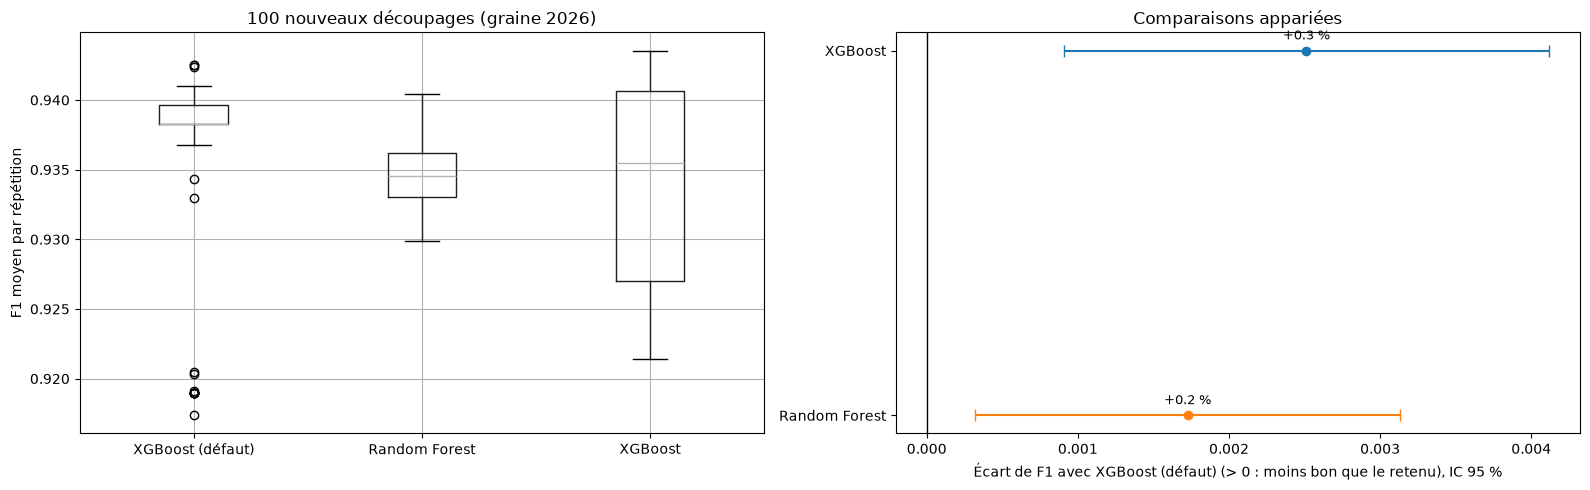

In [27]:
# 5) Représentations
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

ax = axes[0]
par_rep[resume.index].boxplot(ax=ax)
ax.set_ylabel(f"{score} moyen par répétition{unite}")
ax.set_title(f"{N_REPETITIONS} nouveaux découpages (graine {SEED_REEVAL})")

ax = axes[1]
ypos = np.arange(len(comp))
for y_, (nom, row) in zip(ypos, comp.iterrows()):
    ax.errorbar(row["ecart_moyen"], y_,
                xerr=[[row["ecart_moyen"] - row["IC95_bas"]],
                      [row["IC95_haut"] - row["ecart_moyen"]]],
                fmt="o", capsize=4)
    ax.annotate(f"{row['ecart_relatif_%']:+.1f} %", (row["ecart_moyen"], y_),
                textcoords="offset points", xytext=(0, 8), ha="center", fontsize=9)
ax.axvline(0, c="k", lw=1)
ax.set_yticks(ypos, comp.index)
ax.invert_yaxis()
ax.set_xlabel(f"Écart de {score} avec {nom_final} (> 0 : moins bon que le retenu), IC 95 %")
ax.set_title("Comparaisons appariées")

plt.tight_layout()
plt.show()

**Évaluation finale.** Le modèle retenu est réentraîné sur tout le train, puis évalué **une seule fois** sur le test. On le compare à la référence naïve. L'intervalle de confiance du score de test est obtenu par **bootstrap sur les séries `Weld ID`** : on tire des séries entières avec remise, car les soudures d'une même série ne sont pas indépendantes.

In [28]:
# ==================================================================
# 6) Évaluation finale, UNE SEULE FOIS, sur le jeu de test
#    (à lancer après la 5 ter, qui fixe nom_final)
# ==================================================================

# Scores de CV de référence : ceux des nouveaux découpages (5 ter)
cv_final = reeval[reeval["modele"] == nom_final][METRIQUES].mean()
score_cv = resume.loc[nom_final, f"{score} moyen"]
cv_bas, cv_haut = resume.loc[nom_final, "IC95 bas"], resume.loc[nom_final, "IC95 haut"]

# ------------------------------------------------------------------
# 6.1) Réentraînement du modèle retenu sur TOUT X_train, puis prédiction du test
# ------------------------------------------------------------------
modele_final = clone(modeles[nom_final])
modele_final.fit(X_train_red, y_train)
y_pred_test = modele_final.predict(X_test_red)
y_proba_test = modele_final.predict_proba(X_test_red)[:, 1] if EST_CLS else None
score_test = metriques_(y_test, y_pred_test, y_proba_test)

# Référence naïve sur le test (moyenne ou classe majoritaire du train), pour situer le score
baseline = make_pipeline(construire_prep(COL_NUM_RED, COL_CAT_RED), make_baseline()).fit(X_train_red, y_train)
proba_base = baseline.predict_proba(X_test_red)[:, 1] if EST_CLS else None
score_base = metriques_(y_test, baseline.predict(X_test_red), proba_base)

print(f"Modèle final : {nom_final}")
print(f"Hyperparamètres : {params[nom_final]}\n")

recap = pd.DataFrame({
    "CV (nouveaux découpages)": cv_final,
    "Test": pd.Series(score_test)[METRIQUES],
    "Baseline sur le test": pd.Series(score_base)[METRIQUES],
})
print(recap.round(3))

# ------------------------------------------------------------------
# 6.2) Intervalle de confiance du score de test (bootstrap par série)
#      On tire des séries Weld ID entières avec remise, car les soudures
#      d'une même série ne sont pas indépendantes.
# ------------------------------------------------------------------
res_test = pd.DataFrame({"groupe": groups.iloc[test_idx].values,
                         "reel": y_test.values,
                         "predit": y_pred_test})
if EST_CLS:
    res_test["proba"] = y_proba_test
par_groupe = {g: df_ for g, df_ in res_test.groupby("groupe")}
noms_groupes = list(par_groupe)

def score_bootstrap(reel, predit):
    return f1_score(reel, predit, zero_division=0) if EST_CLS else root_mean_squared_error(reel, predit)

rng = np.random.default_rng(RANDOM_STATE)
boot_score = []
for _ in range(2000):
    tirage = rng.choice(noms_groupes, size=len(noms_groupes), replace=True)
    ech = pd.concat([par_groupe[g] for g in tirage])
    if EST_CLS and ech["reel"].nunique() < 2:        # on garde les tirages qui contiennent les deux classes
        continue
    boot_score.append(score_bootstrap(ech["reel"], ech["predit"]))
ic_bas, ic_haut = np.percentile(boot_score, [2.5, 97.5])

print(f"\n{score} test = {score_test[score]:.3f}{unite}, intervalle à 95 % : [{ic_bas:.3f} ; {ic_haut:.3f}]")
print(f"{score} CV   = {score_cv:.3f}{unite}, intervalle sur les découpages : [{cv_bas:.3f} ; {cv_haut:.3f}]")

Modèle final : XGBoost (défaut)
Hyperparamètres : {}

                   CV (nouveaux découpages)   Test  Baseline sur le test
F1                                    0.937  0.968                 0.915
Accuracy_ponderee                     0.770  0.824                 0.500
Precision                             0.925  0.938                 0.843
Recall                                0.952  1.000                 1.000
ROC_AUC                               0.912  0.804                 0.500

F1 test = 0.968, intervalle à 95 % : [0.963 ; 1.000]
F1 CV   = 0.937, intervalle sur les découpages : [0.935 ; 0.938]


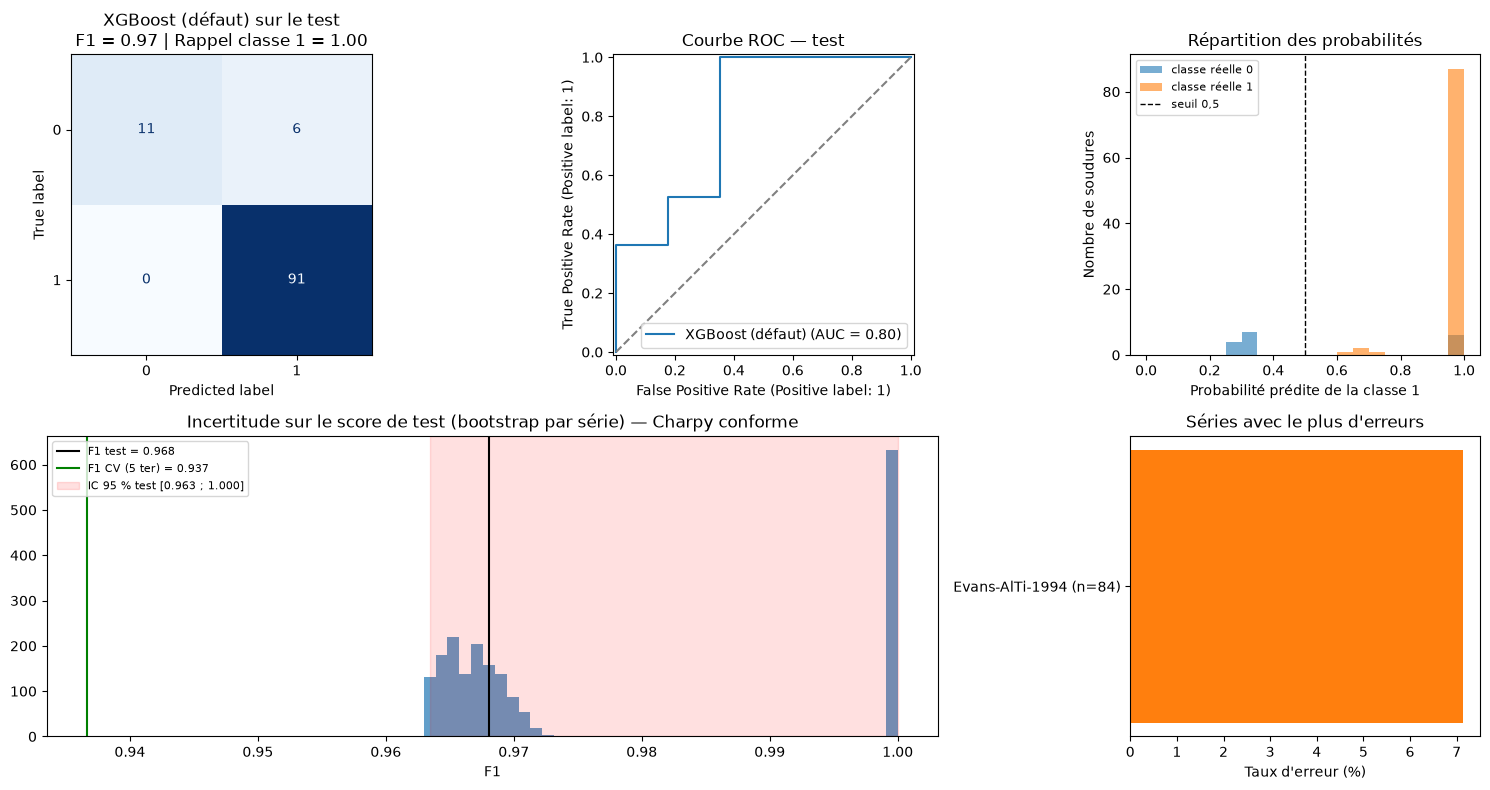

In [29]:
# ------------------------------------------------------------------
# 6.3) Représentations
# ------------------------------------------------------------------
res_test["erreur"] = (res_test["predit"] != res_test["reel"]).astype(int) if EST_CLS else (res_test["predit"] - res_test["reel"]).abs()
err_series = (res_test.groupby("groupe")["erreur"].agg(["mean", "size"])
              .sort_values("mean", ascending=False))
if EST_CLS:
    err_series = err_series[err_series["mean"] > 0]          # séries qui ont au moins une erreur
err_series = err_series.head(8)                              # les 8 pires séries

fig, axd = plt.subplot_mosaic(
    [["a", "b", "c"],
     ["boot", "boot", "err"]],
    figsize=(15, 8))

if EST_CLS:
    # a) Matrice de confusion
    ConfusionMatrixDisplay.from_predictions(
        y_test, y_pred_test, cmap="Blues", ax=axd["a"], colorbar=False)
    axd["a"].set_title(f"{nom_final} sur le test\n{score} = {score_test[score]:.2f} | "
                       f"Rappel classe 1 = {score_test['Recall']:.2f}")

    # b) Courbe ROC
    RocCurveDisplay.from_predictions(y_test, y_proba_test, ax=axd["b"], name=nom_final)
    axd["b"].plot([0, 1], [0, 1], "--", color="grey")
    axd["b"].set_title("Courbe ROC — test")

    # c) Répartition des probabilités prédites de la classe 1, selon la classe réelle
    ax = axd["c"]
    bins = np.linspace(0, 1, 21)
    for classe, couleur in [(0, "#1f77b4"), (1, "#ff7f0e")]:
        ax.hist(res_test.loc[res_test["reel"] == classe, "proba"], bins=bins, alpha=0.6,
                color=couleur, label=f"classe réelle {classe}")
    ax.axvline(0.5, c="k", ls="--", lw=1, label="seuil 0,5")
    ax.set(xlabel="Probabilité prédite de la classe 1", ylabel="Nombre de soudures",
           title="Répartition des probabilités")
    ax.legend(fontsize=8)
else:
    # a) Prédit vs réel
    ax = axd["a"]
    marge = 0.05 * (res_test["reel"].max() - res_test["reel"].min())
    lims = [min(res_test["reel"].min(), res_test["predit"].min()) - marge,
            max(res_test["reel"].max(), res_test["predit"].max()) + marge]
    ax.scatter(res_test["reel"], res_test["predit"], s=18, alpha=0.6)
    ax.plot(lims, lims, "r--", lw=1, label="prédiction parfaite")
    ax.set(xlim=lims, ylim=lims, xlabel=f"Valeur réelle{unite}", ylabel=f"Valeur prédite{unite}",
           title=f"{nom_final} sur le test\nRMSE = {score_test['RMSE']:.1f} | R² = {score_test['R2']:.2f}")
    ax.legend()

    # b) Distribution des résidus
    ax = axd["b"]
    residu = res_test["predit"] - res_test["reel"]
    ax.hist(residu, bins=25, color="#1f77b4", alpha=0.7)
    ax.axvline(0, c="r", ls="--", lw=1)
    ax.axvline(residu.mean(), c="k", lw=1, label=f"biais moyen = {residu.mean():.1f}")
    ax.set(xlabel=f"Résidu = prédit − réel{unite}", ylabel="Nombre de soudures",
           title="Distribution des erreurs sur le test")
    ax.legend(fontsize=8)

    # c) Résidu en fonction de la valeur prédite
    ax = axd["c"]
    ax.scatter(res_test["predit"], residu, s=14, alpha=0.5)
    ax.axhline(0, c="r", ls="--", lw=1)
    ax.set(xlabel=f"Valeur prédite{unite}", ylabel=f"Résidu{unite}", title="Résidus selon la valeur prédite")

# d) Incertitude du score (bootstrap par série), comparée à la CV
ax = axd["boot"]
ax.hist(boot_score, bins=40, color="#1f77b4", alpha=0.7)
ax.axvline(score_test[score], c="k", lw=1.5, label=f"{score} test = {score_test[score]:.3f}")
ax.axvline(score_cv, c="g", lw=1.5, label=f"{score} CV (5 ter) = {score_cv:.3f}")
ax.axvspan(ic_bas, ic_haut, color="red", alpha=0.12, label=f"IC 95 % test [{ic_bas:.3f} ; {ic_haut:.3f}]")
ax.set(xlabel=f"{score}{unite}", title=f"Incertitude sur le score de test (bootstrap par série) — {target}")
ax.legend(fontsize=8, loc="upper left")

# e) Séries du test qui concentrent les erreurs
ax = axd["err"]
ax.barh(err_series.index + " (n=" + err_series["size"].astype(str) + ")",
        err_series["mean"] * (100 if EST_CLS else 1), color="#ff7f0e")
ax.invert_yaxis()
ax.set(xlabel="Taux d'erreur (%)" if EST_CLS else f"Erreur absolue moyenne{unite}",
       title="Séries avec le plus d'erreurs")

plt.tight_layout()
plt.show()

**Diagnostics complémentaires.** Trois graphiques pour vérifier que le classement des modèles est robuste : le score moyen avec son incertitude (et le seuil de la règle 1-SE), la dispersion du score entre les plis, et les métriques côte à côte. On regarde ensuite quelles variables comptent le plus pour le modèle retenu (importance par permutation sur le test), puis ce que donne un Random Forest, à titre de comparaison seulement.

c:\Users\andem\miniconda3\envs\soudure_acier\Lib\site-packages\pandas\plotting\_matplotlib\boxplot.py:408: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  bp = ax.boxplot(values, **kwds)


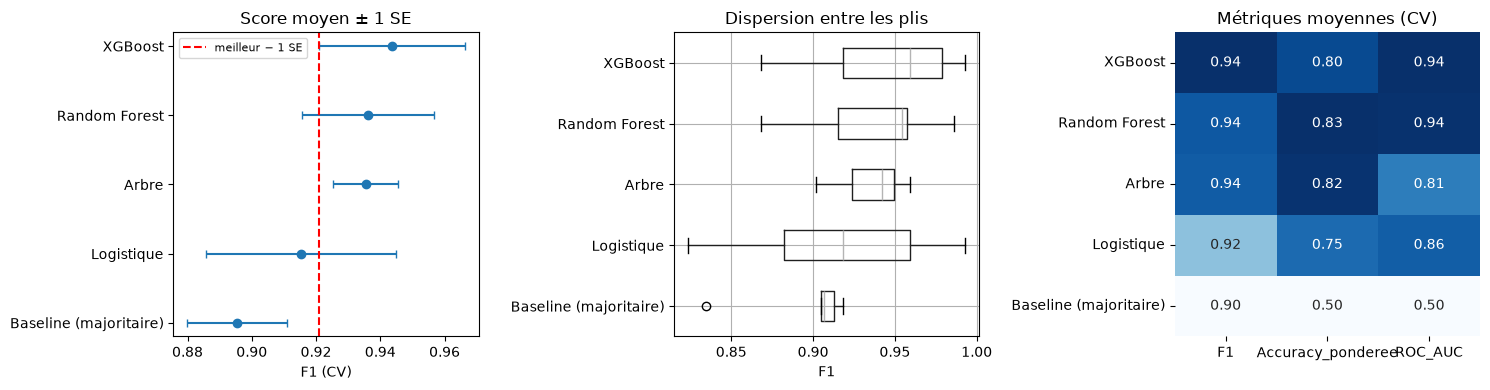

In [30]:
t = tableau.sort_values("moyenne", ascending=(sens == 1))
noms_modeles = [n for n in t.index if n in modeles]          # sans la baseline
best = t.loc[noms_modeles[0]]
metriques_graph = ["F1", "Accuracy_ponderee", "ROC_AUC"] if EST_CLS else ["RMSE", "MAE", "R2"]

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

# A) Score moyen ± 1 SE, avec le seuil de la règle 1-SE
ax = axes[0]
ax.errorbar(t["moyenne"], range(len(t)), xerr=t["SE"], fmt="o", capsize=3)
ax.axvline(best["moyenne"] + sens * best["SE"], ls="--", c="red",
           label=f"meilleur {'+' if sens == 1 else '−'} 1 SE")
ax.set_yticks(range(len(t)), t.index)
ax.invert_yaxis()
ax.set(xlabel=f"{score} (CV){unite}", title="Score moyen ± 1 SE")
ax.legend(fontsize=8)

# B) Dispersion du score entre les plis
ax = axes[1]
pd.DataFrame({nom: s[score] for nom, s in registre.items()})[t.index].boxplot(ax=ax, vert=False)
ax.invert_yaxis()
ax.set(xlabel=f"{score}{unite}", title="Dispersion entre les plis")

# C) Métriques moyennes (la couleur compare les modèles métrique par métrique)
moy = pd.DataFrame({nom: s.mean() for nom, s in registre.items()}).T.loc[t.index, metriques_graph]
relatif = (moy - moy.min()) / (moy.max() - moy.min() + 1e-12)
sns.heatmap(relatif, annot=moy, fmt=".2f", cmap="Blues", cbar=False, ax=axes[2])
axes[2].set_title("Métriques moyennes (CV)")

plt.tight_layout()
plt.show()

**Importance des variables.** On mélange une variable à la fois sur le jeu de test : plus le score se dégrade, plus la variable compte pour le modèle retenu.

,variable,importance moyenne,écart-type
24,CE_IIW,0.047,0.005
6,Chromium concentration,0.047,0.005
2,Manganese concentration,0.045,0.006
8,Vanadium concentration,0.041,0.006
12,Nitrogen concentration,0.040,0.006
11,Titanium concentration,0.017,0.005
1,Silicon concentration,0.012,0.005
16,Current,0.010,0.001
3,Sulphur concentration,0.010,0.001
7,Molybdenum concentration,0.000,0.000


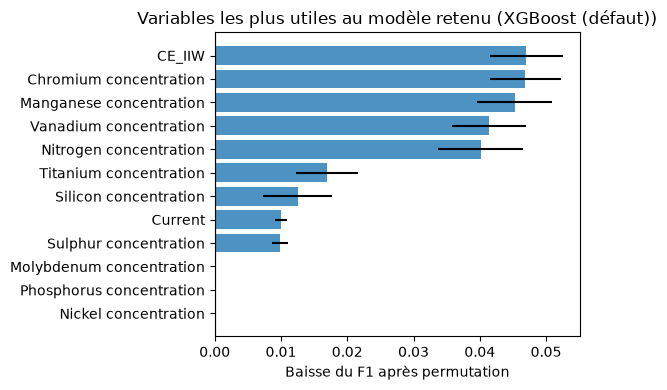

In [31]:
# Importance par permutation : on mélange une variable du test et on mesure la dégradation du score
importance = permutation_importance(
    modele_final, X_test_red, y_test, scoring=scoring_forward,
    n_repeats=30, random_state=RANDOM_STATE, n_jobs=-1,
)
importance_df = (
    pd.DataFrame({
        "variable": X_test_red.columns,
        "importance moyenne": importance.importances_mean,
        "écart-type": importance.importances_std,
    })
    .sort_values("importance moyenne", ascending=False)
)
display(importance_df.head(12).round(3))

top = importance_df.head(12).sort_values("importance moyenne")
fig, ax = plt.subplots(figsize=(6, 4))
ax.barh(top["variable"], top["importance moyenne"], xerr=top["écart-type"], alpha=.8)
ax.axvline(0, color="black", lw=.8)
ax.set(
    xlabel="Baisse du F1 après permutation" if EST_CLS else f"Hausse du RMSE après permutation{unite}",
    title=f"Variables les plus utiles au modèle retenu ({nom_final})",
)
plt.tight_layout()
plt.show()

**Enregistrement des résultats** de cette méthode pour la cible étudiée (tous les tableaux, les prédictions du test, les hyperparamètres et le modèle entraîné).

In [33]:
enregistrer_analyse("A_sans_selection")

Charpy conforme — « A_sans_selection » enregistrée dans : C:\Users\andem\Documents\Marilyne_HU\Cycle ingénieur - CentraleSupélec\Ingenieur_3A\ApprAuto\Soudure-d-acier\1. Données\05_reporting\prediction_Charpy conforme\Charpy_conforme\A_sans_selection
cv_comparaison_modeles.csv
  - cv_scores_par_fold.csv
  - finalistes_comparaisons_appariees.csv
  - finalistes_reeval_brut.csv
  - finalistes_resume.csv
  - importance_permutation_random_forest.csv
  - importance_permutation_retenu.csv
  - modele_final.joblib
  - modele_retenu.json
  - test_bootstrap.csv
  - test_comparaison_random_forest.csv
  - test_predictions.csv
  - test_recap_metriques.csv
  - variables.csv


#### B. Méthode avec sélection de variables

On applique les choix de la sélection forward : seules les variables gardées sont utilisées. Le reste de la démarche est identique à la méthode A.

In [34]:
# ==================================================================
# 0) Données : on applique les choix de la sélection forward
# ==================================================================
cols_gardees = best_feats
cols_supprimees = [f for f in X_train_fe.columns if f not in best_feats]
print("Colonnes supprimées :", cols_supprimees)

X_train_red = X_train_fe.drop(columns=cols_supprimees)
X_test_red = X_test_fe.drop(columns=cols_supprimees)
COL_NUM_RED = [c for c in COL_NUM if c not in cols_supprimees]
COL_CAT_RED = [c for c in COL_CAT if c not in cols_supprimees]

# Folds : les MÊMES pour tous les modèles, groupés sur Weld ID, calculés sur tout X_train
groups_train = groups.iloc[train_idx]
y_bins_train = y_bins.iloc[train_idx]
folds = list(sgkf.split(X_train_red, y_bins_train, groups_train))

Colonnes supprimées : ['Manganese concentration', 'Sulphur concentration', 'Phosphorus concentration', 'Nickel concentration', 'Molybdenum concentration', 'Vanadium concentration', 'Copper concentration', 'Nitrogen concentration', 'Aluminium concentration', 'Boron concentration', 'Niobium concentration', 'Current', 'Heat input', 'Interpass temperature', 'Type of weld', 'Post weld heat treatment temperature', 'Post weld heat treatment time', 'courant', 'CE_IIW']


**Comparaison des modèles réglés.** On évalue d'abord la référence naïve (rien à régler), puis chaque modèle avec Optuna et la règle 1-SE, avec le même budget d'essais pour tous.

In [35]:
registre = {}   # nom du modèle -> DataFrame des scores par fold

# Affichage des erreurs pour l'optimisation
optuna.logging.set_verbosity(optuna.logging.WARNING)

# Référence naïve : prédit toujours la moyenne (régression) ou la classe majoritaire (classification)
registre[NOM_BASELINE] = evaluer(make_pipeline(construire_prep(COL_NUM_RED, COL_CAT_RED), make_baseline()),
                                 X_train_red, y_train, folds)

modeles, params = {}, {}

# Régression linéaire classique (régression seulement) : rien à régler, évaluation directe
if not EST_CLS:
    lin = make_pipeline(construire_prep(COL_NUM_RED, COL_CAT_RED), StandardScaler(), LinearRegression())
    registre["Régression linéaire"] = evaluer(lin, X_train_red, y_train, folds)
    modeles["Régression linéaire"], params["Régression linéaire"] = lin, {}

# Modèles avec hyperparamètres réglés par Optuna
for nom, fn in MODELES:
    modeles[nom], params[nom] = optimiser(nom, fn, X_train_red, y_train, construire_prep(COL_NUM_RED, COL_CAT_RED), registre, n_trials=n_TRIALS)

Logistique : 99/100 essais indiscernables, retenu n°62 (0.922 vs meilleur 0.922)
Arbre : 66/100 essais indiscernables, retenu n°13 (0.932 vs meilleur 0.946)
Random Forest : 90/100 essais indiscernables, retenu n°33 (0.960 vs meilleur 0.961)
XGBoost : 79/100 essais indiscernables, retenu n°86 (0.960 vs meilleur 0.969)


                        moyenne  ecart_type     SE  pire_fold
Random Forest             0.960       0.053  0.024      0.868
XGBoost                   0.960       0.058  0.026      0.859
Arbre                     0.932       0.055  0.025      0.846
Logistique                0.922       0.036  0.016      0.868
Baseline (majoritaire)    0.895       0.035  0.015      0.834


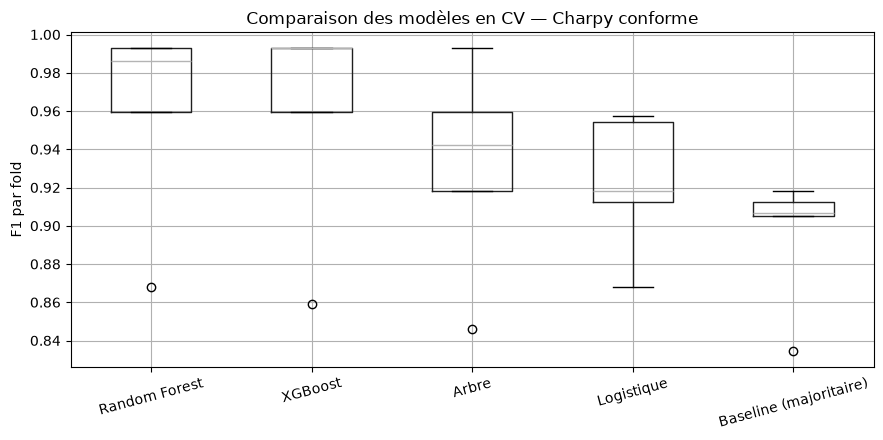

In [36]:
# 5) Comparaison des modèles réglés
tableau = (pd.DataFrame({nom: resumer_(s) for nom, s in registre.items()}).T
           .sort_values("moyenne", ascending=(sens == 1)))
print(tableau.round(3))

# Boxplot du score par fold
fig, ax = plt.subplots(figsize=(9, 4.5))
pd.DataFrame({nom: s[score] for nom, s in registre.items()})[tableau.index].boxplot(ax=ax)
ax.set_ylabel(f"{score} par fold{unite}")
ax.set_title(f"Comparaison des modèles en CV — {target}")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

**Choix des finalistes.** Pour mesurer l'apport réel de l'optimisation, on ajoute un **XGBoost avec ses hyperparamètres par défaut**, évalué avec les mêmes variables et les mêmes plis. Si les modèles optimisés ne le battent pas nettement, le réglage n'apporte rien.

Les **finalistes** sont les deux meilleurs modèles optimisés du tableau précédent et ce XGBoost par défaut. Seuls ces trois modèles passent à l'étape suivante, ce qui limite le risque de surestimer la performance en choisissant parmi trop de candidats.

In [37]:
# ==================================================================
# 5 bis) Choix des finalistes (aucune décision ici)
# ==================================================================
# Version par défaut : mesure le gain réel de l'optimisation
modeles["XGBoost (défaut)"] = make_pipeline(
    construire_prep(COL_NUM_RED, COL_CAT_RED), make_xgb_defaut())
params["XGBoost (défaut)"] = {}
registre["XGBoost (défaut)"] = evaluer(modeles["XGBoost (défaut)"],
                                       X_train_red, y_train, folds)

# Les 2 meilleurs modèles optimisés du benchmark + la version par défaut
top2 = [n for n in tableau.index if n in modeles][:2]
FINALISTES = top2 + ["XGBoost (défaut)"]
print("Finalistes :", FINALISTES)

Finalistes : ['Random Forest', 'XGBoost', 'XGBoost (défaut)']


**Départage des finalistes sur de nouveaux découpages.**

*Le problème.* Avec peu de séries de soudure (`Weld ID`), le score d'un modèle dépend beaucoup de la façon dont les séries sont réparties entre les 5 plis. Deux modèles proches peuvent changer de rang d'un découpage à l'autre : le classement obtenu plus haut peut donc être dû au hasard du découpage, et non à une vraie supériorité.

*La méthode.* On répète la validation croisée avec **100 graines différentes**, donc 100 découpages différents en 5 plis, soit 100 × 5 évaluations par modèle. Les hyperparamètres sont figés (ils ont déjà été choisis avec Optuna), donc on ne mesure que l'effet du découpage. Les graines sont différentes de `RANDOM_STATE`, pour ne pas réutiliser les plis qui ont servi au réglage.

*Ce qu'on en tire.*
- Un **score moyen** par modèle, bien plus stable qu'un score obtenu sur un seul découpage.
- Un **intervalle de confiance à 95 %** sur ce score moyen, pour savoir si deux modèles sont vraiment différents.
- La **dispersion** d'un pli à l'autre et le **pire pli**, qui montrent la fiabilité du modèle dans le cas défavorable.

*La règle de choix* est fixée **avant** le calcul : le modèle retenu est celui dont le score moyen sur toutes les répétitions est le meilleur, sans exception. On évite ainsi de choisir le modèle après avoir regardé les résultats.

Cette étape ne sert qu'à choisir parmi les 3 finalistes. Le test, lui, n'est toujours pas utilisé.

In [38]:
# ==================================================================
# 5 ter) Départage des finalistes sur de NOUVEAUX découpages
# ==================================================================
# Règle pré-enregistrée, écrite AVANT le calcul :
#   le modèle retenu est celui dont le score moyen sur toutes les
#   répétitions est le meilleur. Aucune exception.
SEED_REEVAL = 2026        # graine différente de RANDOM_STATE
N_REPETITIONS = 30        # 30 x 5 folds = 150 entraînements par modèle

# 1) Évaluation sur les mêmes nouveaux découpages, hyperparamètres figés
lignes = []
for r in range(N_REPETITIONS):
    folds_r = list(StratifiedGroupKFold(n_splits=5, shuffle=True,
                                        random_state=SEED_REEVAL + r)
                   .split(X_train_red, y_bins_train, groups_train))
    for nom in FINALISTES:
        s = evaluer(modeles[nom], X_train_red, y_train, folds_r)
        s["modele"], s["repetition"], s["fold"] = nom, r, range(len(s))
        lignes.append(s)
reeval = pd.concat(lignes, ignore_index=True)

par_rep  = reeval.pivot_table(index="repetition", columns="modele", values=score)[FINALISTES]
par_fold = reeval.pivot_table(index=["repetition", "fold"], columns="modele", values=score)[FINALISTES]

In [39]:
# 2) Résumé : deux niveaux de lecture
#    - répétition -> incertitude sur la moyenne (IC 95 %)
#    - fold       -> dispersion et pire cas
m  = par_rep.mean()
se = par_rep.std() / np.sqrt(N_REPETITIONS)
resume = pd.DataFrame({
    f"{score} moyen":  m,
    "IC95 bas":        m - 1.96 * se,
    "IC95 haut":       m + 1.96 * se,
    "écart-type fold": par_fold.std(),
    "pire fold":       par_fold.max() if sens == 1 else par_fold.min(),
})
for autre in METRIQUES:
    if autre != score:
        resume[autre] = reeval.groupby("modele")[autre].mean()
resume = resume.sort_values(f"{score} moyen", ascending=(sens == 1))
print(resume.round(3).to_string())

                  F1 moyen  IC95 bas  IC95 haut  écart-type fold  pire fold  Accuracy_ponderee  Precision  Recall  ROC_AUC
modele                                                                                                                    
XGBoost              0.960     0.959      0.960            0.052      0.859              0.874      0.957   0.962    0.927
Random Forest        0.959     0.959      0.960            0.047      0.868              0.888      0.964   0.955    0.940
XGBoost (défaut)     0.942     0.942      0.942            0.044      0.868              0.784      0.931   0.956    0.916


In [40]:
# 3) Application de la règle
nom_final = resume.index[0]
print(f"\nModèle retenu (règle pré-enregistrée) : {nom_final}")


Modèle retenu (règle pré-enregistrée) : XGBoost


In [41]:
# 4) Comparaisons appariées avec le retenu (lecture, pas décision)
comp = []
for nom in FINALISTES:
    if nom == nom_final:
        continue
    d_ = sens * (par_rep[nom] - par_rep[nom_final])          # > 0 : moins bon que le retenu
    se_d = d_.std() / np.sqrt(len(d_))
    comp.append({
        "modele": nom,
        "ecart_moyen": d_.mean(),
        "IC95_bas": d_.mean() - 1.96 * se_d,
        "IC95_haut": d_.mean() + 1.96 * se_d,
        "t apparié": d_.mean() / se_d,
        "ecart_relatif_%": 100 * d_.mean() / m[nom_final],
        "rep_gagnees_par_retenu_%": 100 * (d_ > 0).mean(),
        "folds_gagnes_par_retenu_%": 100 * (sens * (par_fold[nom] - par_fold[nom_final]) > 0).mean(),
    })
comp = pd.DataFrame(comp).set_index("modele")
print(comp.round(3).to_string())

                  ecart_moyen  IC95_bas  IC95_haut  t apparié  ecart_relatif_%  rep_gagnees_par_retenu_%  folds_gagnes_par_retenu_%
modele                                                                                                                             
Random Forest           0.000    -0.000      0.001      1.602            0.032                      40.0                       20.0
XGBoost (défaut)        0.017     0.017      0.018    190.832            1.808                     100.0                       60.0


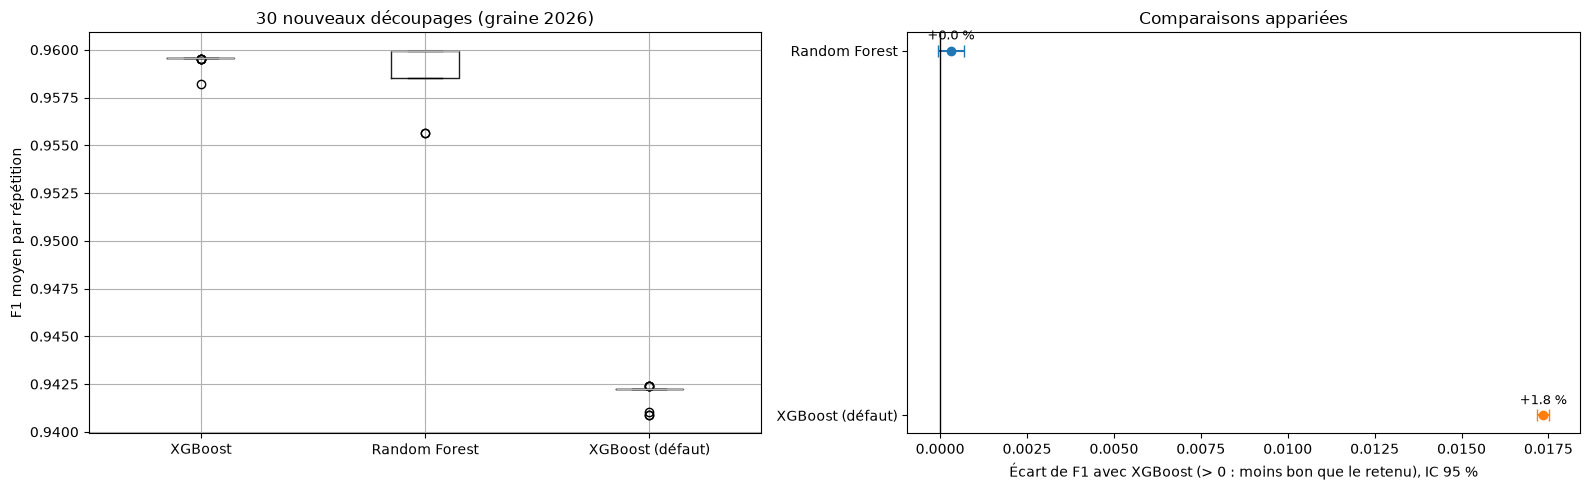

In [42]:
# 5) Représentations
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

ax = axes[0]
par_rep[resume.index].boxplot(ax=ax)
ax.set_ylabel(f"{score} moyen par répétition{unite}")
ax.set_title(f"{N_REPETITIONS} nouveaux découpages (graine {SEED_REEVAL})")

ax = axes[1]
ypos = np.arange(len(comp))
for y_, (nom, row) in zip(ypos, comp.iterrows()):
    ax.errorbar(row["ecart_moyen"], y_,
                xerr=[[row["ecart_moyen"] - row["IC95_bas"]],
                      [row["IC95_haut"] - row["ecart_moyen"]]],
                fmt="o", capsize=4)
    ax.annotate(f"{row['ecart_relatif_%']:+.1f} %", (row["ecart_moyen"], y_),
                textcoords="offset points", xytext=(0, 8), ha="center", fontsize=9)
ax.axvline(0, c="k", lw=1)
ax.set_yticks(ypos, comp.index)
ax.invert_yaxis()
ax.set_xlabel(f"Écart de {score} avec {nom_final} (> 0 : moins bon que le retenu), IC 95 %")
ax.set_title("Comparaisons appariées")

plt.tight_layout()
plt.show()

**Évaluation finale.** Le modèle retenu est réentraîné sur tout le train, puis évalué **une seule fois** sur le test. On le compare à la référence naïve. L'intervalle de confiance du score de test est obtenu par **bootstrap sur les séries `Weld ID`** : on tire des séries entières avec remise, car les soudures d'une même série ne sont pas indépendantes.

In [43]:
# ==================================================================
# 6) Évaluation finale, UNE SEULE FOIS, sur le jeu de test
#    (à lancer après la 5 ter, qui fixe nom_final)
# ==================================================================

# Scores de CV de référence : ceux des nouveaux découpages (5 ter)
cv_final = reeval[reeval["modele"] == nom_final][METRIQUES].mean()
score_cv = resume.loc[nom_final, f"{score} moyen"]
cv_bas, cv_haut = resume.loc[nom_final, "IC95 bas"], resume.loc[nom_final, "IC95 haut"]

# ------------------------------------------------------------------
# 6.1) Réentraînement du modèle retenu sur TOUT X_train, puis prédiction du test
# ------------------------------------------------------------------
modele_final = clone(modeles[nom_final])
modele_final.fit(X_train_red, y_train)
y_pred_test = modele_final.predict(X_test_red)
y_proba_test = modele_final.predict_proba(X_test_red)[:, 1] if EST_CLS else None
score_test = metriques_(y_test, y_pred_test, y_proba_test)

# Référence naïve sur le test (moyenne ou classe majoritaire du train), pour situer le score
baseline = make_pipeline(construire_prep(COL_NUM_RED, COL_CAT_RED), make_baseline()).fit(X_train_red, y_train)
proba_base = baseline.predict_proba(X_test_red)[:, 1] if EST_CLS else None
score_base = metriques_(y_test, baseline.predict(X_test_red), proba_base)

print(f"Modèle final : {nom_final}")
print(f"Hyperparamètres : {params[nom_final]}\n")

recap = pd.DataFrame({
    "CV (nouveaux découpages)": cv_final,
    "Test": pd.Series(score_test)[METRIQUES],
    "Baseline sur le test": pd.Series(score_base)[METRIQUES],
})
print(recap.round(3))

# ------------------------------------------------------------------
# 6.2) Intervalle de confiance du score de test (bootstrap par série)
#      On tire des séries Weld ID entières avec remise, car les soudures
#      d'une même série ne sont pas indépendantes.
# ------------------------------------------------------------------
res_test = pd.DataFrame({"groupe": groups.iloc[test_idx].values,
                         "reel": y_test.values,
                         "predit": y_pred_test})
if EST_CLS:
    res_test["proba"] = y_proba_test
par_groupe = {g: df_ for g, df_ in res_test.groupby("groupe")}
noms_groupes = list(par_groupe)

def score_bootstrap(reel, predit):
    return f1_score(reel, predit, zero_division=0) if EST_CLS else root_mean_squared_error(reel, predit)

rng = np.random.default_rng(RANDOM_STATE)
boot_score = []
for _ in range(2000):
    tirage = rng.choice(noms_groupes, size=len(noms_groupes), replace=True)
    ech = pd.concat([par_groupe[g] for g in tirage])
    if EST_CLS and ech["reel"].nunique() < 2:        # on garde les tirages qui contiennent les deux classes
        continue
    boot_score.append(score_bootstrap(ech["reel"], ech["predit"]))
ic_bas, ic_haut = np.percentile(boot_score, [2.5, 97.5])

print(f"\n{score} test = {score_test[score]:.3f}{unite}, intervalle à 95 % : [{ic_bas:.3f} ; {ic_haut:.3f}]")
print(f"{score} CV   = {score_cv:.3f}{unite}, intervalle sur les découpages : [{cv_bas:.3f} ; {cv_haut:.3f}]")

Modèle final : XGBoost
Hyperparamètres : {'n_estimators': 103, 'learning_rate': 0.18016580639035568, 'max_depth': 6, 'subsample': 0.6794106491195451, 'colsample_bytree': 0.8728475997797337, 'min_child_weight': 3}

                   CV (nouveaux découpages)   Test  Baseline sur le test
F1                                    0.960  0.896                 0.915
Accuracy_ponderee                     0.874  0.531                 0.500
Precision                             0.957  0.851                 0.843
Recall                                0.962  0.945                 1.000
ROC_AUC                               0.927  0.917                 0.500

F1 test = 0.896, intervalle à 95 % : [0.065 ; 0.963]
F1 CV   = 0.960, intervalle sur les découpages : [0.959 ; 0.960]


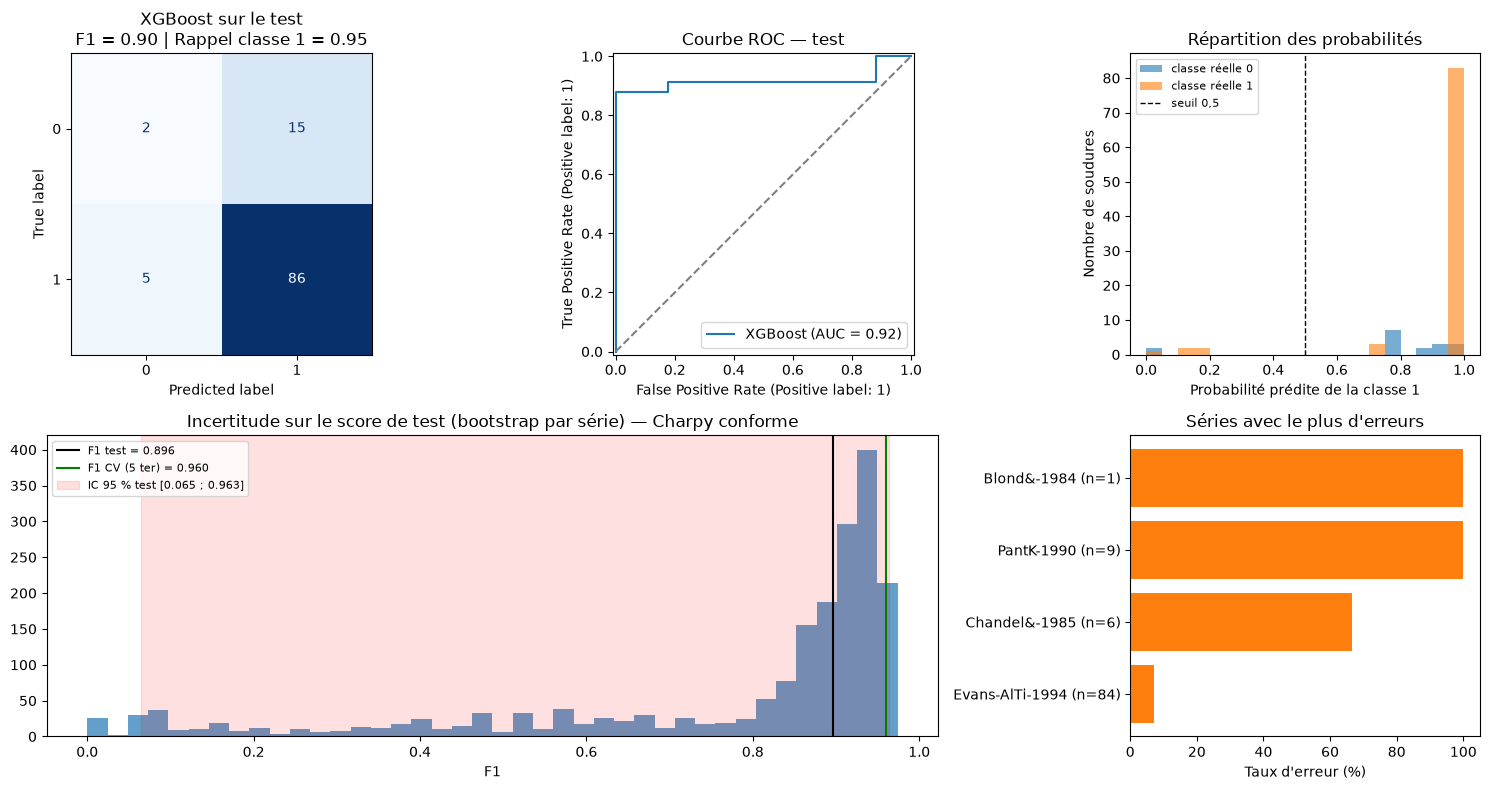

In [44]:
# ------------------------------------------------------------------
# 6.3) Représentations
# ------------------------------------------------------------------
res_test["erreur"] = (res_test["predit"] != res_test["reel"]).astype(int) if EST_CLS else (res_test["predit"] - res_test["reel"]).abs()
err_series = (res_test.groupby("groupe")["erreur"].agg(["mean", "size"])
              .sort_values("mean", ascending=False))
if EST_CLS:
    err_series = err_series[err_series["mean"] > 0]          # séries qui ont au moins une erreur
err_series = err_series.head(8)                              # les 8 pires séries

fig, axd = plt.subplot_mosaic(
    [["a", "b", "c"],
     ["boot", "boot", "err"]],
    figsize=(15, 8))

if EST_CLS:
    # a) Matrice de confusion
    ConfusionMatrixDisplay.from_predictions(
        y_test, y_pred_test, cmap="Blues", ax=axd["a"], colorbar=False)
    axd["a"].set_title(f"{nom_final} sur le test\n{score} = {score_test[score]:.2f} | "
                       f"Rappel classe 1 = {score_test['Recall']:.2f}")

    # b) Courbe ROC
    RocCurveDisplay.from_predictions(y_test, y_proba_test, ax=axd["b"], name=nom_final)
    axd["b"].plot([0, 1], [0, 1], "--", color="grey")
    axd["b"].set_title("Courbe ROC — test")

    # c) Répartition des probabilités prédites de la classe 1, selon la classe réelle
    ax = axd["c"]
    bins = np.linspace(0, 1, 21)
    for classe, couleur in [(0, "#1f77b4"), (1, "#ff7f0e")]:
        ax.hist(res_test.loc[res_test["reel"] == classe, "proba"], bins=bins, alpha=0.6,
                color=couleur, label=f"classe réelle {classe}")
    ax.axvline(0.5, c="k", ls="--", lw=1, label="seuil 0,5")
    ax.set(xlabel="Probabilité prédite de la classe 1", ylabel="Nombre de soudures",
           title="Répartition des probabilités")
    ax.legend(fontsize=8)
else:
    # a) Prédit vs réel
    ax = axd["a"]
    marge = 0.05 * (res_test["reel"].max() - res_test["reel"].min())
    lims = [min(res_test["reel"].min(), res_test["predit"].min()) - marge,
            max(res_test["reel"].max(), res_test["predit"].max()) + marge]
    ax.scatter(res_test["reel"], res_test["predit"], s=18, alpha=0.6)
    ax.plot(lims, lims, "r--", lw=1, label="prédiction parfaite")
    ax.set(xlim=lims, ylim=lims, xlabel=f"Valeur réelle{unite}", ylabel=f"Valeur prédite{unite}",
           title=f"{nom_final} sur le test\nRMSE = {score_test['RMSE']:.1f} | R² = {score_test['R2']:.2f}")
    ax.legend()

    # b) Distribution des résidus
    ax = axd["b"]
    residu = res_test["predit"] - res_test["reel"]
    ax.hist(residu, bins=25, color="#1f77b4", alpha=0.7)
    ax.axvline(0, c="r", ls="--", lw=1)
    ax.axvline(residu.mean(), c="k", lw=1, label=f"biais moyen = {residu.mean():.1f}")
    ax.set(xlabel=f"Résidu = prédit − réel{unite}", ylabel="Nombre de soudures",
           title="Distribution des erreurs sur le test")
    ax.legend(fontsize=8)

    # c) Résidu en fonction de la valeur prédite
    ax = axd["c"]
    ax.scatter(res_test["predit"], residu, s=14, alpha=0.5)
    ax.axhline(0, c="r", ls="--", lw=1)
    ax.set(xlabel=f"Valeur prédite{unite}", ylabel=f"Résidu{unite}", title="Résidus selon la valeur prédite")

# d) Incertitude du score (bootstrap par série), comparée à la CV
ax = axd["boot"]
ax.hist(boot_score, bins=40, color="#1f77b4", alpha=0.7)
ax.axvline(score_test[score], c="k", lw=1.5, label=f"{score} test = {score_test[score]:.3f}")
ax.axvline(score_cv, c="g", lw=1.5, label=f"{score} CV (5 ter) = {score_cv:.3f}")
ax.axvspan(ic_bas, ic_haut, color="red", alpha=0.12, label=f"IC 95 % test [{ic_bas:.3f} ; {ic_haut:.3f}]")
ax.set(xlabel=f"{score}{unite}", title=f"Incertitude sur le score de test (bootstrap par série) — {target}")
ax.legend(fontsize=8, loc="upper left")

# e) Séries du test qui concentrent les erreurs
ax = axd["err"]
ax.barh(err_series.index + " (n=" + err_series["size"].astype(str) + ")",
        err_series["mean"] * (100 if EST_CLS else 1), color="#ff7f0e")
ax.invert_yaxis()
ax.set(xlabel="Taux d'erreur (%)" if EST_CLS else f"Erreur absolue moyenne{unite}",
       title="Séries avec le plus d'erreurs")

plt.tight_layout()
plt.show()

**Diagnostics complémentaires.** Trois graphiques pour vérifier que le classement des modèles est robuste : le score moyen avec son incertitude (et le seuil de la règle 1-SE), la dispersion du score entre les plis, et les métriques côte à côte. On regarde ensuite quelles variables comptent le plus pour le modèle retenu (importance par permutation sur le test), puis ce que donne un Random Forest, à titre de comparaison seulement.

c:\Users\andem\miniconda3\envs\soudure_acier\Lib\site-packages\pandas\plotting\_matplotlib\boxplot.py:408: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  bp = ax.boxplot(values, **kwds)


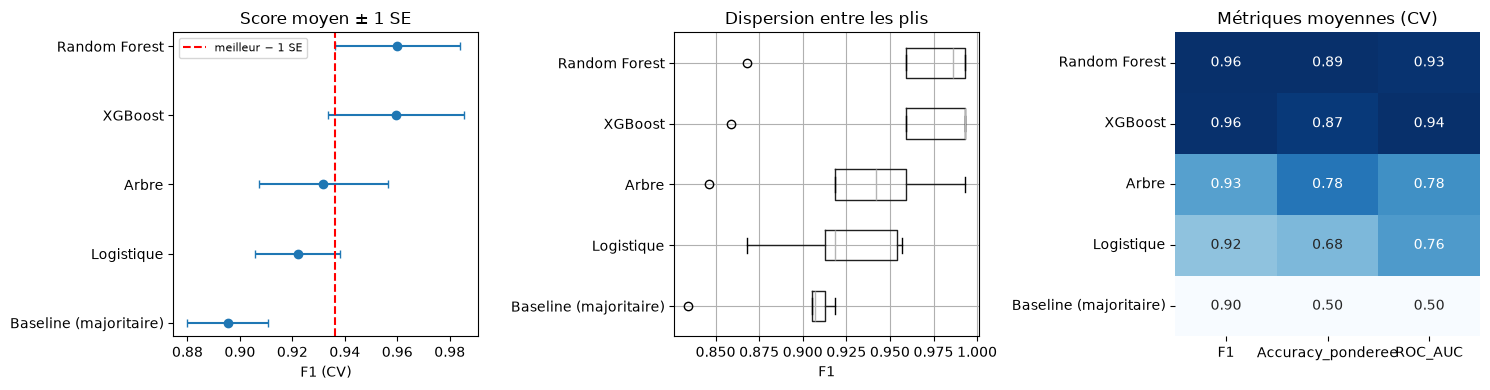

In [45]:
t = tableau.sort_values("moyenne", ascending=(sens == 1))
noms_modeles = [n for n in t.index if n in modeles]          # sans la baseline
best = t.loc[noms_modeles[0]]
metriques_graph = ["F1", "Accuracy_ponderee", "ROC_AUC"] if EST_CLS else ["RMSE", "MAE", "R2"]

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

# A) Score moyen ± 1 SE, avec le seuil de la règle 1-SE
ax = axes[0]
ax.errorbar(t["moyenne"], range(len(t)), xerr=t["SE"], fmt="o", capsize=3)
ax.axvline(best["moyenne"] + sens * best["SE"], ls="--", c="red",
           label=f"meilleur {'+' if sens == 1 else '−'} 1 SE")
ax.set_yticks(range(len(t)), t.index)
ax.invert_yaxis()
ax.set(xlabel=f"{score} (CV){unite}", title="Score moyen ± 1 SE")
ax.legend(fontsize=8)

# B) Dispersion du score entre les plis
ax = axes[1]
pd.DataFrame({nom: s[score] for nom, s in registre.items()})[t.index].boxplot(ax=ax, vert=False)
ax.invert_yaxis()
ax.set(xlabel=f"{score}{unite}", title="Dispersion entre les plis")

# C) Métriques moyennes (la couleur compare les modèles métrique par métrique)
moy = pd.DataFrame({nom: s.mean() for nom, s in registre.items()}).T.loc[t.index, metriques_graph]
relatif = (moy - moy.min()) / (moy.max() - moy.min() + 1e-12)
sns.heatmap(relatif, annot=moy, fmt=".2f", cmap="Blues", cbar=False, ax=axes[2])
axes[2].set_title("Métriques moyennes (CV)")

plt.tight_layout()
plt.show()

**Importance des variables.** On mélange une variable à la fois sur le jeu de test : plus le score se dégrade, plus la variable compte pour le modèle retenu.

,variable,importance moyenne,écart-type
0,Carbon concentration,0.000,0.000
1,Silicon concentration,0.000,0.000
4,Titanium concentration,0.000,0.000
3,Oxygen concentration,-0.005,0.003
5,Voltage,-0.008,0.011
2,Chromium concentration,-0.011,0.008


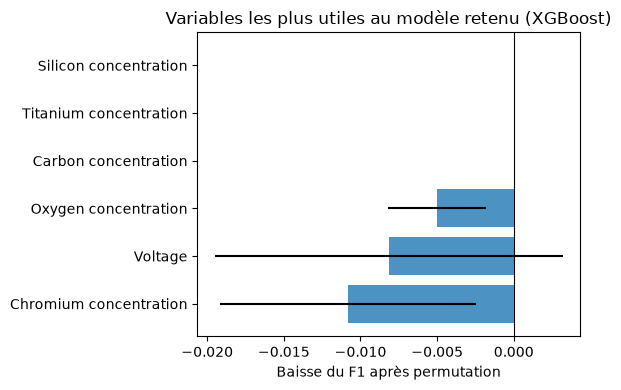

In [46]:
# Importance par permutation : on mélange une variable du test et on mesure la dégradation du score
importance = permutation_importance(
    modele_final, X_test_red, y_test, scoring=scoring_forward,
    n_repeats=30, random_state=RANDOM_STATE, n_jobs=-1,
)
importance_df = (
    pd.DataFrame({
        "variable": X_test_red.columns,
        "importance moyenne": importance.importances_mean,
        "écart-type": importance.importances_std,
    })
    .sort_values("importance moyenne", ascending=False)
)
display(importance_df.head(12).round(3))

top = importance_df.head(12).sort_values("importance moyenne")
fig, ax = plt.subplots(figsize=(6, 4))
ax.barh(top["variable"], top["importance moyenne"], xerr=top["écart-type"], alpha=.8)
ax.axvline(0, color="black", lw=.8)
ax.set(
    xlabel="Baisse du F1 après permutation" if EST_CLS else f"Hausse du RMSE après permutation{unite}",
    title=f"Variables les plus utiles au modèle retenu ({nom_final})",
)
plt.tight_layout()
plt.show()

**Enregistrement des résultats** de cette méthode pour la cible étudiée (tous les tableaux, les prédictions du test, les hyperparamètres et le modèle entraîné).

In [48]:
enregistrer_analyse("B_avec_selection", forward=(models, cv_scores, best_feats))

Charpy conforme — « B_avec_selection » enregistrée dans : C:\Users\andem\Documents\Marilyne_HU\Cycle ingénieur - CentraleSupélec\Ingenieur_3A\ApprAuto\Soudure-d-acier\1. Données\05_reporting\prediction_Charpy conforme\Charpy_conforme\B_avec_selection
cv_comparaison_modeles.csv
  - cv_scores_par_fold.csv
  - finalistes_comparaisons_appariees.csv
  - finalistes_reeval_brut.csv
  - finalistes_resume.csv
  - importance_permutation_random_forest.csv
  - importance_permutation_retenu.csv
  - modele_final.joblib
  - modele_retenu.json
  - selection_forward.csv
  - test_bootstrap.csv
  - test_comparaison_random_forest.csv
  - test_predictions.csv
  - test_recap_metriques.csv
  - variables.csv


## Conclusion

Ce notebook permet de prédire chacun des 5 indicateurs de qualité avec la même démarche : split par série de soudure, imputation, sélection forward, comparaison de modèles réglés avec Optuna (règle 1-SE), puis évaluation unique sur le test avec un intervalle de confiance.

Pour chaque cible, deux méthodes sont comparées : **A** (toutes les variables) et **B** (avec sélection forward). Les résultats complets de chaque analyse sont enregistrés dans `05_reporting/prediction_par_cible/<cible>/<méthode>/`, et le tableau de synthèse dans `05_reporting/resultats_par_cible.csv`.

**À compléter après avoir exécuté les 5 cibles :** pour chaque cible, le modèle retenu, son score de test comparé à la référence naïve, et le choix entre les méthodes A et B. Les cibles pour lesquelles le modèle ne fait pas nettement mieux que la référence naïve montrent la limite de la prédiction indicateur par indicateur, ce qui motive la construction d'une cible unique (notebooks 4 et 5).